# Netflix (NFLX): is the stock flat between earnings, with its volatility concentrated in the releases?

A reproducible test of four hypotheses about NFLX's daily price behaviour across eleven years of
quarterly earnings cycles (the Q3-2015 release in October 2015 through the Q3-2026 release on
20 October 2026):

* **H1 Low inter-earnings volatility.** Realized volatility between releases is low.
* **H2 Earnings concentration.** A disproportionate share of realized variance comes from earnings moves.
* **H3 Predictability.** Inter-earnings volatility is stable enough to estimate the period's expected range.
* **H4 Unusual contrast.** The earnings vs inter-earnings contrast is larger than for comparable stocks
  or the market.

Sections: 1 data acquisition, 2 earnings calendar, 3 prices and returns, 4 earnings-cycle segmentation,
5 realized volatility, 6 variance decomposition, 7 benchmark comparisons, 8 statistical tests (including
"does NFLX trade sideways?" and the options-market evidence), 9 charts, 10 results summary.

**Running it.** `python src/pull_all.py` and `python src/pull_options.py` download and cache every raw
input under `data/raw/`. The notebook only reads that cache, so it re-runs offline on identical inputs
(set `REFRESH = True` to re-download prices, filings and the Cboe chain). The only manual input is
`data/manual/earnings_calendar_adjustments.csv`: documented exclusions of 8-K Item 2.02 filings that
are not earnings releases, one timing override, and the hand-identified Spotify 6-K list.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib

if "ipykernel" not in sys.modules:   # plain-script run: render to files only
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator
from matplotlib.gridspec import GridSpec
from scipy import stats
import statsmodels.api as sm

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import data_sources as ds  # noqa: E402
import evol  # noqa: E402
import calendars  # noqa: E402
import vizstyle as vz  # noqa: E402

try:
    from IPython.display import display
except ImportError:  # running as a plain script
    display = print

import logging  # noqa: E402

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="FigureCanvasAgg is non-interactive")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
vz.apply()
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 120)

REFRESH = False            # True re-downloads prices, filings and the Cboe chain
FIRST_EVENT = "2015-10-01" # first release in the sample: Q3-2015 (14-Oct-2015)
ANN = evol.ANN             # 252 trading days per year
B = 10_000                 # bootstrap / randomization replications
L = 4                      # block length in cycles (4 cycles ~ 1 year of volatility regime)
SEED = 20261025
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
PROC.mkdir(parents=True, exist_ok=True)
CHARTS.mkdir(parents=True, exist_ok=True)


def pct(x, d=1):
    return np.round(100 * np.asarray(x, dtype=float), d)

## 1. Data acquisition

**Prices.** Daily open, high, low, close, volume, the split- and dividend-adjusted close, split events and
dividend events from the Yahoo Finance chart API (the endpoint `yfinance` wraps), June 2014 to
23 October 2026. The extra history before the first event feeds the rolling market betas.

**Adjustments.** Every OHLC field is multiplied by adjclose/close, so returns are total returns and
no split creates an artificial jump. NFLX pays no dividend, so for NFLX this only handles the
7-for-1 split (15-Jul-2015) and the 10-for-1 split (17-Nov-2025).

**Universe.** NFLX; SPY (S&P 500) and QQQ (Nasdaq-100) as market benchmarks; thirteen peers in three
groups:
* *Mega-cap tech / internet* (AAPL, MSFT, AMZN, GOOGL, META, NVDA, TSLA): the large-cap growth stocks
  NFLX trades with, with comparable institutional ownership, factor exposure and option liquidity.
* *Large-cap software / online platforms* (ADBE, CRM, BKNG): consumer- or subscription-driven
  businesses whose quarterly prints regularly move the stock 5-10%.
* *Media & streaming* (DIS, SPOT, ROKU): the closest business-model comparables. SPOT listed in
  April 2018 and ROKU in September 2017, and ROKU is a mid-cap for much of the sample, so both have
  shorter samples and are flagged in the tables.

In [2]:
BENCH = ["SPY", "QQQ"]
PEER_GROUPS = {
    "Mega-cap tech / internet": ["AAPL", "MSFT", "AMZN", "GOOGL", "META", "NVDA", "TSLA"],
    "Large-cap software / platforms": ["ADBE", "CRM", "BKNG"],
    "Media & streaming": ["DIS", "SPOT", "ROKU"],
}
PEERS = [t for g in PEER_GROUPS.values() for t in g]
GROUP_OF = {t: g for g, ts in PEER_GROUPS.items() for t in ts}
STOCKS = ["NFLX"] + PEERS
TICKERS = STOCKS + BENCH

px, corp, quality = {}, {}, []
for t in TICKERS:
    raw, ev = ds.yahoo_daily(t, refresh=REFRESH)
    px[t] = evol.prep_prices(raw)
    corp[t] = ev
    quality.append(evol.validate_prices(px[t], t, ev.loc[ev["type"] == "splits", "date"]))
quality = pd.DataFrame(quality).set_index("ticker")
display(quality)

,rows,first,last,missing_ohlc,nonpositive_px,high_below_open_or_close,low_above_open_or_close,zero_volume_days,calendar_gaps_gt_4d,zero_overnight_returns,adj_factor_min,max_abs_r,max_abs_r_date,max_abs_return_on_split_dates
ticker,,,,,,,,,,,,,,
NFLX,3119,2014-06-02,2026-10-23,0,0,0,0,0,0,41,1.000000,0.432578,2022-04-20,0.022584
AAPL,3119,2014-06-02,2026-10-23,0,0,0,0,0,0,0,0.876183,0.142617,2025-04-09,0.033350
MSFT,3119,2014-06-02,2026-10-23,0,0,0,0,0,0,0,0.836497,0.159453,2020-03-16,0.000000
AMZN,3119,2014-06-02,2026-10-23,0,0,0,0,0,0,24,1.000000,0.151398,2022-04-29,0.023426
GOOGL,3119,2014-06-02,2026-10-23,0,0,0,0,0,0,0,0.990574,0.150645,2015-07-17,0.024887
META,3119,2014-06-02,2026-10-23,0,0,0,0,0,0,0,0.990513,0.306391,2022-02-03,0.000000
NVDA,3119,2014-06-02,2026-10-23,0,0,0,0,0,0,0,0.949309,0.260877,2016-11-11,0.008973
TSLA,3119,2014-06-02,2026-10-23,0,0,0,0,0,0,10,1.000000,0.236518,2020-09-08,0.118395
ADBE,3119,2014-06-02,2026-10-23,0,0,0,0,0,0,54,1.000000,0.183841,2022-09-15,0.000000


**Data-quality reading.** No missing OHLC values, no high/low inconsistencies, no zero-volume days and
no gaps longer than a holiday weekend in any series. The largest absolute return on any split date is
shown in the last column. Split days look like ordinary days, so the adjustment is clean.
One known Yahoo artefact remains: on a few days the reported open equals the previous close exactly,
which moves that day's overnight return into the intraday return. The close-to-close analysis is
unaffected. The overnight/intraday split is checked below for exposure on earnings days.

In [3]:
nf = px["NFLX"]
print(corp["NFLX"].to_string(index=False))
print("NFLX cash dividends:", int((corp["NFLX"]["type"] == "dividends").sum()))
f = nf["adjclose"] / nf["close"]
print(f"adjclose/close for NFLX: min {f.min():.6f}, max {f.max():.6f} (1.0 = no dividend adjustment)")
for d in ["2015-07-15", "2025-11-17"]:
    d = pd.Timestamp(d)
    w = nf.loc[d - pd.Timedelta(days=4): d + pd.Timedelta(days=4), ["open", "close", "volume", "r", "o"]]
    print(f"\nAround the split on {d.date()} (prices are split-adjusted):")
    display(w.round(4))
assert nf.index.equals(px["SPY"].index), "NFLX and SPY trading calendars differ"
print("NFLX and SPY share the same trading calendar:", nf.index.equals(px["SPY"].index))

      date   type value
2015-07-15 splits   7:1
2025-11-17 splits  10:1
NFLX cash dividends: 0
adjclose/close for NFLX: min 1.000000, max 1.000000 (1.0 = no dividend adjustment)

Around the split on 2015-07-15 (prices are split-adjusted):


,open,close,volume,r,o
date,,,,,
2015-07-13,9.8099,10.1087,332052000,0.0389,0.0089
2015-07-14,10.1271,10.0371,197365000,-0.0071,0.0018
2015-07-15,9.9970,9.8130,308986000,-0.0226,-0.0040
2015-07-16,11.1020,11.5810,634610000,0.1657,0.1234
2015-07-17,11.7340,11.4770,251369000,-0.0090,0.0131



Around the split on 2025-11-17 (prices are split-adjusted):


,open,close,volume,r,o
date,,,,,
2025-11-13,115.850,115.423,40144000,-0.0028,0.0009
2025-11-14,114.273,111.217,47607000,-0.0371,-0.0100
2025-11-17,110.750,110.290,26082700,-0.0084,-0.0042
2025-11-18,110.290,114.090,43440600,0.0339,0.0000
2025-11-19,113.000,110.000,31868100,-0.0365,-0.0096
2025-11-20,111.000,105.670,36918500,-0.0402,0.0090
2025-11-21,105.130,104.310,41232700,-0.0130,-0.0051


NFLX and SPY share the same trading calendar: True


## 2. Earnings calendar construction

**Source.** Every SEC 8-K that carries Item 2.02 ("Results of Operations and Financial Condition"), from the
EDGAR submissions API. Its acceptance timestamp (UTC, converted to US Eastern) dates the release and tells
us whether it came before the open (before 09:30 ET, BMO), after the close (16:00 ET or later, AMC) or
during the session (DMH). Netflix publishes its shareholder letter at about 16:01 ET and furnishes it
on 8-K within minutes, so the acceptance time is a tight bound on the release time.

**Reaction day R.** AMC release on day E: R = the next trading day, the overnight return into R carries the
after-hours reaction, and E's own session is pre-release. BMO release on day E: R = E. An 8-K accepted
during the session is assigned to that day and flagged. If a company files the 8-K the morning after an
AMC release, it gets classified BMO for the next day. The reaction day is the same either way.

**Manual adjustments** (below) remove Item 2.02 filings that are not scheduled earnings releases:
pre-announcements, restatements and recasts, and Tesla's delivery reports. They also fix one timing
and list Spotify's results 6-Ks, since a foreign private issuer files no 8-K. Each row gives its reason.

In [4]:
adj = calendars.adjustments()
display(adj[adj["ticker"] != "SPOT"])
print(f"(plus {int((adj['ticker'] == 'SPOT').sum())} hand-identified Spotify results 6-Ks)")

EVENTS, EVENTS_ALL, checks = {}, {}, []
for t in STOCKS:
    ev_all = calendars.events_for(t, px[t].index, start="2014-01-01")
    EVENTS_ALL[t] = ev_all
    ev = ev_all[ev_all["react"] >= FIRST_EVENT].reset_index(drop=True)
    EVENTS[t] = ev
    chk, s = calendars.check_events(px[t], ev)
    row = {"ticker": t, **{k: v for k, v in s.items() if k != "timing_counts"}}
    row.update({f"n_{k}": v for k, v in s["timing_counts"].items()})
    checks.append(row)
checks = pd.DataFrame(checks).set_index("ticker").fillna(0)
display(checks.round(5))

,ticker,primary_document,action,value,reason
0,NFLX,a2019reclass8-k.htm,exclude,,2-Jan-2019 8-K (Item 2.02) reclassification fi...
1,NFLX,nflx-20191216.htm,exclude,,16-Dec-2019 8-K disclosing regional membership...
2,AAPL,a8-kjanuary2019122019.htm,exclude,,2-Jan-2019 letter cutting Q1 FY19 revenue guid...
3,GOOGL,goog-20230420.htm,exclude,,20-Apr-2023 recast of segment results; the Q1-...
4,NVDA,form8-kq4fy19update.htm,exclude,,28-Jan-2019 revenue pre-announcement; schedule...
5,NVDA,nvda-20220808.htm,exclude,,8-Aug-2022 revenue pre-announcement; scheduled...
6,CRM,revisedguidance.htm,exclude,,2-Apr-2018 guidance revision tied to the MuleS...
7,BKNG,a8-knonxgaapnewmethodology.htm,exclude,,6-Oct-2016 non-GAAP methodology change
8,BKNG,a8kearnings93017.htm,timing,BMO,8-K accepted 12:15 ET on 7-Nov-2017 but the pr...
9,ROKU,roku-8k_20200413.htm,exclude,,14-Apr-2020 preliminary Q1 results and guidanc...


(plus 35 hand-identified Spotify results 6-Ks)


,events,mean_r2_Rm1,mean_r2_R,mean_r2_Rp1,share_R_is_largest_of_3,flags_neighbour,flags_spacing,n_AMC,n_BMO
ticker,,,,,,,,,
NFLX,45,0.00036,0.01231,0.00087,0.77778,6,0,45,0.0
AAPL,44,0.00027,0.00196,0.00038,0.59091,2,0,44,0.0
MSFT,44,0.00032,0.00254,0.00032,0.75000,1,0,44,0.0
AMZN,44,0.00109,0.00471,0.00050,0.70455,3,0,44,0.0
GOOGL,44,0.00043,0.00292,0.00042,0.75000,3,0,44,0.0
META,45,0.00059,0.01117,0.00034,0.80000,5,0,45,0.0
NVDA,44,0.00048,0.00812,0.00170,0.63636,8,0,44,0.0
TSLA,45,0.00054,0.00751,0.00137,0.73333,6,0,45,0.0
ADBE,44,0.00058,0.00530,0.00099,0.79545,2,0,41,3.0


**Calendar checks.** For every company the mean squared return peaks on the assigned reaction day R,
far above R-1 and R+1, so no systematic timing error is present. Spacing between events is always 35-85
trading days (no missing or duplicate quarters). The flagged events are days where a neighbouring day
moved more than the earnings day. For NFLX all six are small earnings moves followed by a larger
next-day move (e.g. 21-Apr-2025, after the Good Friday close). They are genuine, so nothing is edited.

In [5]:
def nflx_quarter(d):
    return f"Q4-{d.year - 1}" if d.month <= 2 else f"Q{(d.month - 1) // 3}-{d.year}"


nev = EVENTS["NFLX"].copy()
nev["quarter"] = [nflx_quarter(d) for d in nev["ann_date"]]
display(nev[["quarter", "accepted_et", "timing", "ann_date", "react", "pre"]])
zero_open = set(nf.index[nf["o"].abs() < 1e-12])
print("NFLX releases in sample:", len(nev), "| timing:", nev["timing"].value_counts().to_dict())
print("Reaction days whose open equals the prior close (would corrupt the gap):",
      sorted(set(nev["react"]) & zero_open) or "none")
nev.to_csv(PROC / "nflx_earnings_calendar.csv", index=False)

,quarter,accepted_et,timing,ann_date,react,pre
0,Q3-2015,2015-10-14 16:11:06,AMC,2015-10-14,2015-10-15,2015-10-14
1,Q4-2015,2016-01-19 16:13:20,AMC,2016-01-19,2016-01-20,2016-01-19
2,Q1-2016,2016-04-18 16:11:43,AMC,2016-04-18,2016-04-19,2016-04-18
3,Q2-2016,2016-07-18 16:05:15,AMC,2016-07-18,2016-07-19,2016-07-18
4,Q3-2016,2016-10-17 16:16:21,AMC,2016-10-17,2016-10-18,2016-10-17
5,Q4-2016,2017-01-18 16:08:16,AMC,2017-01-18,2017-01-19,2017-01-18
6,Q1-2017,2017-04-17 16:22:12,AMC,2017-04-17,2017-04-18,2017-04-17
7,Q2-2017,2017-07-17 16:16:03,AMC,2017-07-17,2017-07-18,2017-07-17
8,Q3-2017,2017-10-16 16:15:14,AMC,2017-10-16,2017-10-17,2017-10-16
9,Q4-2017,2018-01-22 16:09:34,AMC,2018-01-22,2018-01-23,2018-01-22


NFLX releases in sample: 45 | timing: {'AMC': 45}
Reaction days whose open equals the prior close (would corrupt the gap): none


All 45 NFLX releases were furnished after the close (16:01-16:57 ET). The earnings reaction is therefore
always the overnight gap into the next session plus that session. No reaction day suffers the
open-equals-previous-close artefact.

## 3. Price and return calculations

* close-to-close: r_t = ln(C_t / C_{t-1})
* overnight: o_t = ln(O_t / C_{t-1})
* intraday: i_t = ln(C_t / O_t), so r_t = o_t + i_t exactly

All on adjusted prices. The table lists every release with the last close before it, the first
open and close after it, the overnight gap, the first full session and the close-to-close
earnings return (simple %).

In [6]:
print("max |r - (o + i)| =", float((nf["r"] - (nf["o"] + nf["i"])).abs().max()))
p = nf.index.get_indexer(nev["react"])
evt = pd.DataFrame({
    "quarter": nev["quarter"].to_numpy(),
    "release_et": nev["accepted_et"].dt.strftime("%Y-%m-%d %H:%M").to_numpy(),
    "reaction_day": nev["react"].dt.date.to_numpy(),
    "close_before": nf["close_a"].to_numpy()[p - 1],
    "open_after": nf["open_a"].to_numpy()[p],
    "close_after": nf["close_a"].to_numpy()[p],
    "gap_pct": pct(np.expm1(nf["o"].to_numpy()[p]), 2),
    "session_pct": pct(np.expm1(nf["i"].to_numpy()[p]), 2),
    "earnings_ret_pct": pct(np.expm1(nf["r"].to_numpy()[p]), 2),
    "next_day_pct": pct(np.expm1(nf["r"].to_numpy()[p + 1]), 2),
})
evt["abs_earnings_ret_pct"] = evt["earnings_ret_pct"].abs()
display(evt.round(2))
evt.to_csv(PROC / "nflx_earnings_reactions.csv", index=False)

r_R = nf["r"].to_numpy()[p]
o_R = nf["o"].to_numpy()[p]
i_R = nf["i"].to_numpy()[p]
ev_summary = pd.Series({
    "events": len(p),
    "mean |earnings return| %": pct(np.abs(np.expm1(r_R)).mean(), 2),
    "median |earnings return| %": pct(np.median(np.abs(np.expm1(r_R))), 2),
    "RMS earnings log return %": pct(np.sqrt((r_R ** 2).mean()), 2),
    "largest up %": pct(np.expm1(r_R).max(), 2),
    "largest down %": pct(np.expm1(r_R).min(), 2),
    "share of events |move| > 5%": pct((np.abs(np.expm1(r_R)) > 0.05).mean(), 1),
    "share of events |move| > 10%": pct((np.abs(np.expm1(r_R)) > 0.10).mean(), 1),
    "gap's share of earnings-day squared return %": pct((o_R ** 2).sum() / (r_R ** 2).sum(), 1),
    "corr(gap, same-session return)": np.round(np.corrcoef(o_R, i_R)[0, 1], 3),
    "events where session reversed the gap (sign differs) %": pct((np.sign(o_R) != np.sign(i_R)).mean(), 1),
})
display(ev_summary.to_frame("NFLX earnings reactions"))

max |r - (o + i)| = 9.679756995950584e-16


,quarter,release_et,reaction_day,close_before,open_after,close_after,gap_pct,session_pct,earnings_ret_pct,next_day_pct,abs_earnings_ret_pct
0,Q3-2015,2015-10-14 16:11,2015-10-15,11.02,10.38,10.11,-5.86,-2.58,-8.29,-2.08,8.29
1,Q4-2015,2016-01-19 16:13,2016-01-20,10.79,10.89,10.77,0.95,-1.07,-0.14,-5.00,0.14
2,Q1-2016,2016-04-18 16:11,2016-04-19,10.84,9.95,9.43,-8.22,-5.18,-12.97,2.58,12.97
3,Q2-2016,2016-07-18 16:05,2016-07-19,9.88,8.54,8.58,-13.54,0.48,-13.13,2.41,13.13
4,Q3-2016,2016-10-17 16:16,2016-10-18,9.98,11.66,11.88,16.86,1.85,19.03,2.59,19.03
5,Q4-2016,2017-01-18 16:08,2017-01-19,13.33,14.20,13.84,6.57,-2.54,3.86,0.14,3.86
6,Q1-2017,2017-04-17 16:22,2017-04-18,14.73,14.73,14.34,0.06,-2.70,-2.64,-2.51,2.64
7,Q2-2017,2017-07-17 16:16,2017-07-18,16.17,17.61,18.36,8.92,4.25,13.54,0.14,13.54
8,Q3-2017,2017-10-16 16:15,2017-10-17,20.27,20.01,19.95,-1.27,-0.31,-1.58,-1.98,1.58
9,Q4-2017,2018-01-22 16:09,2018-01-23,22.76,25.50,25.03,12.07,-1.87,9.98,4.40,9.98


,NFLX earnings reactions
events,45.000
mean |earnings return| %,8.200
median |earnings return| %,7.350
RMS earnings log return %,11.090
largest up %,19.030
largest down %,-35.120
share of events |move| > 5%,66.700
share of events |move| > 10%,28.900
gap's share of earnings-day squared return %,83.900
"corr(gap, same-session return)",0.136


## 4. Earnings-cycle segmentation

Cycle k runs from reaction day R_k to the last close before release k+1. The **inter-earnings period** is
R_k+1 ... R_{k+1}-1. It starts the day after the reaction and ends with the pre-release close of the
announcement day. The 45 releases give **44 complete cycles**. The current cycle (from 21-Oct-2026)
has two days so far and is excluded.

Per cycle (section-3 metrics of the brief): price before and after the release, gap, earnings-day
return, cumulative return announcement-to-announcement (last close before release k to last close
before release k+1) and over the inter-earnings period alone, closing-price maximum drawdown and
run-up, intraday-low/high adverse and favourable excursions vs the first post-release close,
high-low range, annualized realized volatility, day count, largest absolute daily return, and the
share of days moving less than 1%, 2% and 3%.

In [7]:
lab = evol.label_days(nf.index, nev["react"])
cyc = evol.cycle_table(nf, nev, lab)
cyc.insert(1, "quarter", nev["quarter"].iloc[: len(cyc)].to_numpy())
cyc.to_csv(PROC / "nflx_cycles.csv", index=False)

pct_cols = ["gap", "intraday_R", "ret_R", "ret_R_plus1", "cum_ann_to_ann", "cum_inter", "vol_inter_ann",
            "mdd_close", "runup_close", "mae_intraday", "mfe_intraday", "range_hl", "max_abs_daily",
            "pct_days_lt1", "pct_days_lt2", "pct_days_lt3"]
show = cyc[["quarter", "react_date", "n_inter_days", "px_before", "px_close_after"] + pct_cols].copy()
show[pct_cols] = show[pct_cols] * 100
display(show.round(1))

summ = show[["n_inter_days"] + pct_cols].describe(percentiles=[0.1, 0.5, 0.9]).T
display(summ[["mean", "10%", "50%", "90%", "min", "max"]].round(1))

,quarter,react_date,n_inter_days,px_before,px_close_after,gap,intraday_R,ret_R,ret_R_plus1,cum_ann_to_ann,cum_inter,vol_inter_ann,mdd_close,runup_close,mae_intraday,mfe_intraday,range_hl,max_abs_daily,pct_days_lt1,pct_days_lt2,pct_days_lt3
0,Q3-2015,2015-10-15,64,11.0,10.1,-5.9,-2.6,-8.3,-2.1,-2.1,6.7,47.3,-20.5,34.5,-4.8,31.8,36.6,9.3,23.4,48.4,70.3
1,Q4-2015,2016-01-20,61,10.8,10.8,0.9,-1.1,-0.1,-5.0,0.5,0.6,44.1,-23.2,34.7,-25.8,3.8,29.6,7.7,32.8,59.0,75.4
2,Q1-2016,2016-04-19,62,10.8,9.4,-8.2,-5.2,-13.0,2.6,-8.8,4.7,32.4,-17.4,17.7,-10.1,10.2,20.3,5.7,33.9,62.9,82.3
3,Q2-2016,2016-07-19,63,9.9,8.6,-13.5,0.5,-13.1,2.4,1.0,16.3,28.1,-6.4,23.8,-1.0,24.6,25.6,4.3,50.8,71.4,88.9
4,Q3-2016,2016-10-18,62,10.0,11.9,16.9,1.9,19.0,2.6,33.5,12.2,24.9,-11.1,17.9,-6.8,14.0,20.8,5.5,59.7,83.9,91.9
5,Q4-2016,2017-01-19,60,13.3,13.8,6.6,-2.5,3.9,0.1,10.5,6.4,16.7,-3.9,7.8,-1.0,7.1,8.1,3.0,73.3,90.0,98.3
6,Q1-2017,2017-04-18,62,14.7,14.3,0.1,-2.7,-2.6,-2.5,9.8,12.8,28.4,-11.9,18.7,-3.3,16.4,19.7,5.8,54.8,79.0,90.3
7,Q2-2017,2017-07-18,63,16.2,18.4,8.9,4.2,13.5,0.1,25.3,10.4,26.9,-12.2,22.1,-10.6,10.5,21.0,5.4,54.0,82.5,90.5
8,Q3-2017,2017-10-17,65,20.3,19.9,-1.3,-0.3,-1.6,-2.0,12.3,14.1,24.9,-8.0,23.7,-10.6,14.2,24.8,5.5,53.8,86.2,93.8
9,Q4-2017,2018-01-23,57,22.8,25.0,12.1,-1.9,10.0,4.4,35.2,23.0,46.0,-15.4,32.9,-5.7,33.4,39.1,6.4,24.6,56.1,64.9


,mean,10%,50%,90%,min,max
n_inter_days,61.9,60.0,62.0,64.0,57.0,66.0
gap,-0.6,-11.6,-0.9,11.5,-29.7,16.9
intraday_R,-0.5,-3.7,-0.7,3.7,-7.8,9.4
ret_R,-1.1,-10.2,-2.4,12.5,-35.1,19.0
ret_R_plus1,0.1,-3.4,-0.1,4.1,-6.2,7.2
cum_ann_to_ann,6.5,-25.6,6.3,31.1,-42.2,43.1
cum_inter,7.1,-12.2,6.7,24.9,-23.6,47.8
vol_inter_ann,34.4,23.4,31.1,50.9,16.7,63.5
mdd_close,-14.6,-25.9,-12.4,-6.4,-35.9,-3.9
runup_close,23.3,10.9,22.1,36.7,6.3,51.6


## 5. Realized volatility calculations

For pooled statistics the sample is cut into **event blocks**: block k = [R_k - 2, R_{k+1} - 2). Every
block holds exactly one reaction day and its full ±2-day window, so no window is split between blocks
and each trading day is counted once. That gives 44 blocks covering 13-Oct-2015 to 16-Oct-2026.
Realized variance is the sum of squared daily log returns (not demeaned). Annualized vol is
sqrt(252 × mean squared return).

In [8]:
eb = evol.event_blocks(nf.index, nev["react"], pre=2)
D = nf.join(eb)
D = D[D["block"] >= 0].copy()
K = int(D["block"].nunique())
rel = D["rel"]
cats = {
    "R-2": rel == -2,
    "R-1 (announcement day, pre-release session)": rel == -1,
    "R (first session after the release)": rel == 0,
    "R+1": rel == 1,
    "R+2": rel == 2,
    "Core inter-earnings (R+3 ... next R-3)": rel >= 3,
    "Earnings window ±1 (R-1 ... R+1)": rel.abs() <= 1,
    "Earnings window ±2 (R-2 ... R+2)": rel.abs() <= 2,
    "All inter-earnings days (everything except R)": rel != 0,
    "All days": rel.notna(),
}


def pooled(r):
    r = r.dropna()
    s = np.expm1(r).abs()
    return pd.Series({"days": len(r), "rms_daily_%": 100 * np.sqrt((r ** 2).mean()),
                      "ann_vol_%": 100 * np.sqrt(ANN * (r ** 2).mean()),
                      "mean_abs_%": 100 * s.mean(), "median_abs_%": 100 * s.median()})


vol_tab = pd.DataFrame({k: pooled(D.loc[m, "r"]) for k, m in cats.items()}).T
core_var = (D.loc[cats["Core inter-earnings (R+3 ... next R-3)"], "r"] ** 2).mean()
vol_tab["variance_multiple_vs_core"] = [(D.loc[m, "r"] ** 2).mean() / core_var for m in cats.values()]
print(f"{K} event blocks, {len(D)} trading days, {D.index[0].date()} to {D.index[-1].date()}")
display(vol_tab.round(2))

44 event blocks, 2769 trading days, 2015-10-13 to 2026-10-16


,days,rms_daily_%,ann_vol_%,mean_abs_%,median_abs_%,variance_multiple_vs_core
R-2,44.0,1.96,31.13,1.39,0.96,0.74
"R-1 (announcement day, pre-release session)",44.0,1.89,30.03,1.46,0.98,0.69
R (first session after the release),44.0,11.19,177.64,8.27,7.37,24.19
R+1,44.0,2.94,46.68,2.39,2.18,1.67
R+2,44.0,2.41,38.24,1.87,1.48,1.12
Core inter-earnings (R+3 ... next R-3),2549.0,2.28,36.12,1.65,1.21,1.00
Earnings window ±1 (R-1 ... R+1),132.0,6.77,107.45,4.04,2.44,8.85
Earnings window ±2 (R-2 ... R+2),220.0,5.42,86.10,3.08,1.67,5.68
All inter-earnings days (everything except R),2725.0,2.28,36.18,1.66,1.22,1.00
All days,2769.0,2.66,42.30,1.77,1.25,1.37


**Per-event comparison (brief section 4).** For each release: the first session's move, the realized vol
of the ±1-day window, the realized vol of the inter-earnings period that preceded the release (known
before the event) and of the one that followed it, and the realized vol of every **equivalent
non-earnings window**. Those are all 1-day and 3-day windows inside the same block, at least three
sessions away from the release. Comparing each release with placebo windows from its own block holds
the volatility regime fixed.

In [9]:
rows = []
for k in range(K):
    blk = D[D["block"] == k]
    rr = blk["r"].to_numpy()
    rl = blk["rel"].to_numpy()
    core_idx = np.where(rl >= 3)[0]
    one_day = rr[core_idx] ** 2
    three = np.array([(rr[j - 1:j + 2] ** 2).sum() for j in core_idx if j + 1 < len(rr) and rl[j - 1] >= 3])
    s0 = rr[rl == 0][0] ** 2
    s1 = (rr[np.abs(rl) <= 1] ** 2).sum()
    rows.append({"block": k, "react": blk.index[rl == 0][0].date(),
                 "abs_R_%": 100 * np.sqrt(s0), "rms_pm1_%": 100 * np.sqrt(s1 / 3),
                 "rms_core_%": 100 * np.sqrt(one_day.mean()),
                 "pctile_R_vs_1day": (one_day < s0).mean(), "pctile_pm1_vs_3day": (three < s1).mean(),
                 "R_is_block_max": s0 >= (rr ** 2).max(), "n_core": len(one_day)})
pe = pd.DataFrame(rows)
cyc_vol = cyc.set_index("react_date")["vol_inter_ann"]
pe["vol_inter_before_ann_%"] = [100 * cyc_vol.iloc[k - 1] if k >= 1 else np.nan for k in range(K)]
pe["vol_inter_after_ann_%"] = [100 * cyc_vol.iloc[k] for k in range(K)]
pe["abs_R_ann_equiv_%"] = pe["abs_R_%"] * np.sqrt(ANN)
display(pe.round(3))
display(pd.Series({
    "median |R| / core daily RMS": np.median(pe["abs_R_%"] / pe["rms_core_%"]),
    "median ±1 window RMS / core RMS": np.median(pe["rms_pm1_%"] / pe["rms_core_%"]),
    "mean percentile of R among the block's 1-day windows (null 0.5)": pe["pctile_R_vs_1day"].mean(),
    "share of releases above every core day of their block": (pe["pctile_R_vs_1day"] == 1).mean(),
    "share of releases that are the block's largest move": pe["R_is_block_max"].mean(),
    "mean percentile of ±1 window among the block's 3-day windows": pe["pctile_pm1_vs_3day"].mean(),
}).round(3).to_frame("placebo comparison"))

,block,react,abs_R_%,rms_pm1_%,rms_core_%,pctile_R_vs_1day,pctile_pm1_vs_3day,R_is_block_max,n_core,vol_inter_before_ann_%,vol_inter_after_ann_%,abs_R_ann_equiv_%
0,0,2015-10-15,8.656,5.149,2.986,0.967,0.862,False,60,NaN,47.297,137.406
1,1,2016-01-20,0.139,3.631,2.753,0.053,0.782,False,57,47.297,44.064,2.208
2,2,2016-04-19,13.892,8.316,2.069,1.000,1.000,True,58,44.064,32.412,220.533
3,3,2016-07-19,14.071,8.243,1.759,1.000,1.000,True,59,32.412,28.099,223.376
4,4,2016-10-18,17.419,10.210,1.575,1.000,1.000,True,58,28.099,24.886,276.517
5,5,2017-01-19,3.792,2.197,1.005,1.000,1.000,True,56,24.886,16.735,60.193
6,6,2017-04-18,2.677,2.741,1.800,0.879,0.875,False,58,16.735,28.431,42.501
7,7,2017-07-18,12.702,7.337,1.719,1.000,1.000,True,59,28.431,26.859,201.633
8,8,2017-10-17,1.591,1.735,1.548,0.738,0.847,False,61,26.859,24.929,25.263
9,9,2018-01-23,9.512,6.301,2.906,1.000,1.000,True,53,24.929,45.991,150.996


,placebo comparison
median |R| / core daily RMS,3.529
median ±1 window RMS / core RMS,2.190
mean percentile of R among the block's 1-day windows (null 0.5),0.905
share of releases above every core day of their block,0.523
share of releases that are the block's largest move,0.523
mean percentile of ±1 window among the block's 3-day windows,0.920


**Event-time volatility profile.** RMS daily return by trading-day offset from the nearest reaction day,
pooled over all releases. It shows whether volatility is depressed mid-cycle, elevated on the
pre-release session, or decays after the event.

In [10]:
prof_rel = lab.loc[D.index, "rel"]
prof = (D["r"] ** 2).groupby(prof_rel).agg(["mean", "size"])
prof = prof.loc[-10:10]
prof["rms_%"] = 100 * np.sqrt(prof["mean"])
mid = (lab.loc[D.index, "since"] >= 6) & (lab.loc[D.index, "to_next"] >= 6)
mid_rms = 100 * np.sqrt((D.loc[mid, "r"] ** 2).mean())
print(f"mid-cycle RMS (>= 6 sessions from either release): {mid_rms:.2f}% on {int(mid.sum())} days")
display(prof[["rms_%", "size"]].T.round(2))

mid-cycle RMS (>= 6 sessions from either release): 2.26% on 2285 days


rel,-10.0,-9.0,-8.0,-7.0,-6.0,-5.0,-4.0,-3.0,-2.0,-1.0,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0
rms_%,2.5,2.51,1.83,2.39,2.07,2.55,2.37,2.55,1.96,1.89,11.19,2.94,2.41,1.8,2.19,2.92,2.56,2.32,1.91,2.28,1.85
size,44.0,44.00,44.00,44.00,44.00,44.00,44.00,44.00,44.00,44.00,44.00,44.00,44.00,44.0,44.00,44.00,44.00,44.00,44.00,44.00,44.00


## 6. Variance decomposition

**Close-to-close.** Each day's squared return is assigned to exactly one bucket, so nothing is double
counted. The earnings share = Σ r² on earnings days / Σ r² on all days. Three event windows: the reaction
day only (k = 0), ±1 and ±2 sessions. Each share is compared with its **day fraction**, the share
the window would get if earnings days were ordinary days.

**Inference.** (a) A 95% confidence interval from a circular moving-block bootstrap over event blocks
(blocks of L = 4 consecutive cycles, B = 10,000). It respects the within-cycle dependence and
the persistence of volatility regimes across adjacent cycles. (b) A randomization test. In every block
the real reaction day is replaced by a randomly chosen day (or 3-/5-day window) from the same block,
10,000 times, giving the null distribution of the share if release days were exchangeable with any
other day in their own cycle.

In [11]:
bs = evol.block_sums(D, "r")
st = evol.stats_from_sums(bs)
IDX = evol.mbb_matrix(K, L, B, SEED)
bt = evol.boot_stats(bs, IDX)

rng = np.random.default_rng(SEED)
null = {0: np.zeros(B), 1: np.zeros(B), 2: np.zeros(B)}
for k in range(K):
    rr2 = (D.loc[D["block"] == k, "r"].to_numpy()) ** 2
    n_k = len(rr2)
    for w in (0, 1, 2):
        sums = np.convolve(rr2, np.ones(2 * w + 1), mode="valid")   # all windows fully inside the block
        null[w] += sums[rng.integers(0, len(sums), B)]
T_total = bs["T"].sum()
dec = []
for w, name in [(0, "Reaction day only"), (1, "±1 session"), (2, "±2 sessions")]:
    obs = st[f"share{w}"]
    lo, hi = evol.ci(bt[f"share{w}"])
    nshare = null[w] / T_total
    dec.append({"window": name, "share_of_variance_%": 100 * obs, "ci95_lo_%": 100 * lo, "ci95_hi_%": 100 * hi,
                "day_fraction_%": 100 * st[f"dayfrac{w}"], "concentration_x": obs / st[f"dayfrac{w}"],
                "null_median_%": 100 * np.median(nshare), "null_p99_%": 100 * np.quantile(nshare, 0.99),
                "randomization_p": (1 + (nshare >= obs).sum()) / (1 + B)})
dec = pd.DataFrame(dec).set_index("window")
display(dec.round(4))

,share_of_variance_%,ci95_lo_%,ci95_hi_%,day_fraction_%,concentration_x,null_median_%,null_p99_%,randomization_p
window,,,,,,,,
Reaction day only,28.0163,15.3309,39.2627,1.5890,17.6312,1.2983,10.5719,0.0001
±1 session,30.7518,18.7537,41.4479,4.7671,6.4509,4.2212,14.4255,0.0001
±2 sessions,32.9103,21.1093,43.2729,7.9451,4.1422,6.5990,17.0060,0.0001


**Overnight vs intraday.** Splitting every day into its overnight (o) and session (i) return gives a
two-observations-per-day realized variance, Σ(o² + i²). It differs from close-to-close RV by the cross
term 2Σ o·i, which is reported separately rather than forced into a bucket. For an AMC release the
earnings gap is o_R and the first full session is i_R.

In [12]:
isR = D["rel"] == 0
inW = D["rel"].abs() <= 1
o2, i2, oi = D["o"] ** 2, D["i"] ** 2, D["o"] * D["i"]
sub = pd.Series({
    "Earnings overnight gap (o on R)": o2[isR].sum(),
    "Earnings first session (i on R)": i2[isR].sum(),
    "Other overnight returns": o2[~isR].sum(),
    "Other sessions (non-earnings intraday)": i2[~isR].sum(),
})
sub_tab = pd.DataFrame({"sum_sq": sub, "share_of_subdaily_RV_%": 100 * sub / sub.sum(),
                        "days": [isR.sum(), isR.sum(), (~isR).sum(), (~isR).sum()]})
sub_tab["ann_vol_contribution_%"] = 100 * np.sqrt(ANN * sub_tab["sum_sq"] / len(D))
display(sub_tab.round(4))
recon = pd.Series({
    "close-to-close RV  Σr²": (D["r"] ** 2).sum(),
    "sub-daily RV  Σ(o²+i²)": sub.sum(),
    "cross term 2Σo·i (all days)": 2 * oi.sum(),
    "cross term on reaction days": 2 * oi[isR].sum(),
    "identity check Σr² - Σ(o²+i²) - 2Σo·i": (D["r"] ** 2).sum() - sub.sum() - 2 * oi.sum(),
})
display(recon.to_frame("value").round(6))
w1 = pd.Series({
    "±1 window overnight": o2[inW].sum(), "±1 window sessions": i2[inW].sum(),
    "outside-window overnight": o2[~inW].sum(), "outside-window sessions": i2[~inW].sum()})
display((100 * w1 / w1.sum()).round(2).to_frame("share of sub-daily RV, ±1 window %"))

,sum_sq,share_of_subdaily_RV_%,days,ann_vol_contribution_%
Earnings overnight gap (o on R),0.4603,23.9874,44,20.4666
Earnings first session (i on R),0.0447,2.3301,44,6.3788
Other overnight returns,0.3240,16.8859,2725,17.1718
Other sessions (non-earnings intraday),1.0898,56.7966,2725,31.4931


,value
close-to-close RV Σr²,1.966531
sub-daily RV Σ(o²+i²),1.918807
cross term 2Σo·i (all days),0.047724
cross term on reaction days,0.045968
identity check Σr² - Σ(o²+i²) - 2Σo·i,-0.000000


,"share of sub-daily RV, ±1 window %"
±1 window overnight,24.45
±1 window sessions,4.61
outside-window overnight,16.42
outside-window sessions,54.51


**Robustness of the share.** Variance shares are dominated by extreme days. The table removes the blocks
containing the 1, 3 and 5 largest earnings moves (which include January and April 2022) and recomputes
the share. It also splits the sample into two halves of 22 cycles.

In [13]:
order = bs["S0"].sort_values(ascending=False).index
rob = {}
for m in (0, 1, 3, 5):
    s_ = evol.stats_from_sums(bs.drop(order[:m]))
    rob[f"drop {m} largest"] = s_
rob["first half (cycles 0-21, 2015-2021)"] = evol.stats_from_sums(bs.iloc[:22])
rob["second half (cycles 22-43, 2021-2026)"] = evol.stats_from_sums(bs.iloc[22:])
rob["excluding the four 2022 cycles"] = evol.stats_from_sums(bs[bs["react"].dt.year != 2022])
rob = pd.DataFrame(rob).T
for c in ["share0", "share1", "share2", "dayfrac0", "rms_R", "vol_inter_ann", "vol_core_ann", "vol_all_ann"]:
    rob[c] = 100 * rob[c]
display(rob[["share0", "share1", "share2", "dayfrac0", "mult", "rms_R", "vol_inter_ann", "vol_core_ann"]].round(2))
print("largest earnings moves (reaction days):",
      [(bs.loc[i, "react"].date(), round(100 * np.sqrt(bs.loc[i, "S0"]), 1)) for i in order[:5]])

,share0,share1,share2,dayfrac0,mult,rms_R,vol_inter_ann,vol_core_ann
drop 0 largest,28.02,30.75,32.91,1.59,24.19,11.19,36.18,36.12
drop 1 largest,21.61,24.67,27.18,1.59,17.20,9.20,35.33,35.21
drop 3 largest,18.09,21.38,23.95,1.59,13.79,8.16,35.01,34.88
drop 5 largest,15.93,19.36,22.01,1.59,11.84,7.62,35.32,35.17
"first half (cycles 0-21, 2015-2021)",18.29,21.66,23.44,1.59,13.87,8.74,37.23,37.26
"second half (cycles 22-43, 2021-2026)",36.55,38.73,41.22,1.59,35.95,13.19,35.09,34.93
excluding the four 2022 cycles,20.13,23.39,25.44,1.59,15.65,8.42,33.81,33.77


largest earnings moves (reaction days): [(datetime.date(2022, 4, 20), np.float64(43.3)), (datetime.date(2022, 1, 21), np.float64(24.6)), (datetime.date(2016, 10, 18), np.float64(17.4)), (datetime.date(2021, 1, 20), np.float64(15.6)), (datetime.date(2023, 10, 19), np.float64(14.9))]


## 7. Benchmark comparisons

Every peer goes through the same pipeline with its own EDGAR release calendar: event blocks, block sums,
the same statistics. **Market-adjusted (idiosyncratic) returns** are e_t = r_t - β_t·r_SPY,t. β_t is the
OLS beta on SPY over the 252 sessions ending at t-1, excluding the stock's own ±1-day earnings windows,
so it uses no future data and is not inflated by earnings days. SPOT and ROKU need 150 sessions of
history before their first beta, so their market-adjusted statistics start later.

Column guide (all annualized vols and shares in %): `vol_inter` = all non-reaction days,
`vol_core` = days ≥ 3 sessions after a release, `rms_R` = RMS earnings-day move, `mult` = earnings-day
variance ÷ core-day variance, `share0/share1` = share of total variance on the reaction day / ±1 window.

In [14]:
SPY_r = px["SPY"]["r"]
XS, BS_R, BS_E, BLK, BETA = {}, {}, {}, {}, {}
for t in STOCKS:
    d0 = px[t]
    lab_t = evol.label_days(d0.index, EVENTS_ALL[t]["react"])
    beta = evol.rolling_beta(d0["r"], SPY_r.reindex(d0.index), lab_t["rel"].abs() <= 1)
    e = d0["r"] - beta * SPY_r.reindex(d0.index)
    d = d0.join(evol.event_blocks(d0.index, EVENTS[t]["react"], pre=2)).assign(e=e, beta=beta)
    d = d[d["block"] >= 0].copy()
    ok = d.groupby("block")["e"].apply(lambda s: bool(s.notna().all()))
    bs_r = evol.block_sums(d, "r")
    bs_e = evol.block_sums(d[d["block"].isin(ok[ok].index)], "e")
    BS_R[t], BS_E[t], BLK[t], BETA[t] = bs_r, bs_e, d, beta
    s_r, s_e = evol.stats_from_sums(bs_r), evol.stats_from_sums(bs_e)
    XS[t] = {"group": "NFLX" if t == "NFLX" else GROUP_OF[t],
             "first_reaction": d.index[d["rel"] == 0][0].date(), "cycles": len(bs_r),
             "vol_all": 100 * s_r["vol_all_ann"], "vol_inter": 100 * s_r["vol_inter_ann"],
             "vol_core": 100 * s_r["vol_core_ann"], "rms_R": 100 * s_r["rms_R"], "mult": s_r["mult"],
             "share0": 100 * s_r["share0"], "share1": 100 * s_r["share1"], "dayfrac0": 100 * s_r["dayfrac0"],
             "idio_vol_inter": 100 * s_e["vol_inter_ann"], "idio_mult": s_e["mult"],
             "idio_share0": 100 * s_e["share0"], "idio_share1": 100 * s_e["share1"],
             "idio_cycles": len(bs_e), "mean_beta": float(beta.reindex(d.index).mean())}
xs = pd.DataFrame(XS).T
for c in xs.columns.drop(["group", "first_reaction"]):
    xs[c] = pd.to_numeric(xs[c])
for c in ["share0", "share1", "mult", "idio_share0", "idio_mult", "vol_inter", "idio_vol_inter", "rms_R"]:
    xs[f"rank_{c}"] = xs[c].rank(ascending=False).astype(int)
display(xs.round(2))
print("NFLX rank among 14 stocks (1 = highest):",
      {c: int(xs.loc["NFLX", f"rank_{c}"]) for c in ["share0", "share1", "mult", "idio_share0", "idio_mult",
                                                    "vol_inter", "idio_vol_inter", "rms_R"]})
xs.to_csv(PROC / "cross_section.csv")

,group,first_reaction,cycles,vol_all,vol_inter,vol_core,rms_R,mult,share0,share1,dayfrac0,idio_vol_inter,idio_mult,idio_share0,idio_share1,idio_cycles,mean_beta,rank_share0,rank_share1,rank_mult,rank_idio_share0,rank_idio_mult,rank_vol_inter,rank_idio_vol_inter,rank_rms_R
NFLX,NFLX,2015-10-15,44,42.30,36.18,36.12,11.19,24.19,28.02,30.75,1.59,29.92,35.01,35.87,38.38,44,1.23,2,2,2,2,2,5,5,2
AAPL,Mega-cap tech / internet,2015-10-28,43,28.88,27.77,27.80,4.33,6.11,9.00,12.12,1.59,17.96,11.96,16.13,20.09,43,1.20,14,13,14,13,13,11,12,14
MSFT,Mega-cap tech / internet,2015-10-23,43,27.22,25.82,25.70,4.60,8.07,11.44,14.83,1.59,15.32,19.35,23.63,26.56,43,1.19,12,12,12,7,7,14,14,13
AMZN,Mega-cap tech / internet,2015-10-23,43,32.62,30.08,29.38,6.60,12.71,16.37,22.21,1.59,20.85,24.54,27.13,33.33,43,1.29,7,6,6,3,3,10,10,9
GOOGL,Mega-cap tech / internet,2015-10-23,43,28.89,27.04,26.80,5.35,10.05,13.78,17.96,1.59,17.84,18.41,22.55,27.27,43,1.17,9,9,9,8,8,12,13,11
META,Mega-cap tech / internet,2015-11-05,44,39.05,32.98,32.80,10.63,26.48,29.83,32.33,1.60,23.94,44.77,41.73,43.94,44,1.30,1,1,1,1,1,6,7,3
NVDA,Mega-cap tech / internet,2015-11-06,43,48.93,45.85,45.60,9.02,9.87,13.57,17.21,1.58,32.66,17.72,21.72,25.82,43,1.87,10,11,10,10,10,3,4,5
TSLA,Mega-cap tech / internet,2015-11-04,44,58.06,55.79,55.70,8.75,6.22,9.14,11.44,1.60,47.77,7.33,10.49,13.23,44,1.64,13,14,13,14,14,2,2,6
ADBE,Large-cap software / platforms,2015-12-11,43,34.76,31.72,31.09,7.36,14.14,18.01,23.07,1.59,23.51,19.63,24.04,26.89,43,1.25,4,4,4,6,6,8,8,7
CRM,Large-cap software / platforms,2015-11-19,43,35.64,32.77,32.60,7.30,12.63,16.79,20.57,1.59,24.76,21.02,24.88,28.77,43,1.24,6,7,7,5,5,7,6,8


NFLX rank among 14 stocks (1 = highest): {'share0': 2, 'share1': 2, 'mult': 2, 'idio_share0': 2, 'idio_mult': 2, 'vol_inter': 5, 'idio_vol_inter': 5, 'rms_R': 2}


**Market benchmarks.** SPY and QQQ have no earnings of their own. They are measured on NFLX's calendar:
their volatility over NFLX's inter-earnings days, and the share of *their* variance that falls on NFLX
reaction days. If NFLX's release days coincided with market-wide turbulence (earnings season, macro
releases), that share would sit well above the 1.6% day fraction.

In [15]:
bench_rows = {}
for b in BENCH:
    db = D[["block", "rel"]].join(px[b][["r"]])
    sb = evol.stats_from_sums(evol.block_sums(db, "r"))
    bench_rows[b] = {"vol_all": 100 * sb["vol_all_ann"], "vol_on_NFLX_inter_days": 100 * sb["vol_inter_ann"],
                     "share_of_var_on_NFLX_R_days": 100 * sb["share0"],
                     "share_of_var_on_NFLX_pm1_windows": 100 * sb["share1"],
                     "var_multiple_on_NFLX_R_days": sb["mult"]}
bench_tab = pd.DataFrame(bench_rows).T
bench_tab.loc["NFLX"] = [xs.loc["NFLX", "vol_all"], xs.loc["NFLX", "vol_inter"], xs.loc["NFLX", "share0"],
                         xs.loc["NFLX", "share1"], xs.loc["NFLX", "mult"]]
display(bench_tab.round(2))

,vol_all,vol_on_NFLX_inter_days,share_of_var_on_NFLX_R_days,share_of_var_on_NFLX_pm1_windows,var_multiple_on_NFLX_R_days
SPY,17.69,17.73,1.09,3.09,0.67
QQQ,22.18,22.21,1.36,3.41,0.83
NFLX,42.30,36.18,28.02,30.75,24.19


**Calendar-quarter bootstrap for the cross-section.** Peers report on different days, but each reports
about once per calendar quarter. Resampling calendar quarters jointly (moving blocks of 4 quarters,
B = 10,000) keeps the cross-sectional correlation, e.g. the 2022 growth sell-off hit everyone in the
same quarters. Each replicate recomputes every stock's statistic from its own blocks in the resampled
quarters. The table gives the confidence interval for NFLX minus the peer median and for NFLX's rank.

In [16]:
quarters = pd.period_range("2015Q4", "2026Q3", freq="Q")
Q = len(quarters)
IDXQ = evol.mbb_matrix(Q, L, B, SEED + 1)


def quarter_map(bsx):
    qs = pd.PeriodIndex(pd.DatetimeIndex(bsx["react"]), freq="Q")
    slots = [[] for _ in range(Q)]
    for pos_, q in enumerate(qs):
        if q in quarters:
            slots[quarters.get_loc(q)].append(pos_)
    m = max(1, max(len(s) for s in slots))
    arr = np.full((Q, m), -1)
    for j, s in enumerate(slots):
        arr[j, :len(s)] = s
    return arr


BT = {}
for kind, store in (("r", BS_R), ("e", BS_E)):
    for t in STOCKS:
        qa = quarter_map(store[t])
        bidx = qa[IDXQ].reshape(B, -1)
        BT[(kind, t)] = evol.boot_stats(store[t], bidx)

xs_ci = []
for kind, stat, label in [("r", "share0", "share of variance on reaction day"),
                          ("r", "share1", "share of variance in ±1 window"),
                          ("r", "mult", "earnings-day variance multiple"),
                          ("r", "vol_inter_ann", "inter-earnings vol (ann.)"),
                          ("e", "share0", "idiosyncratic share on reaction day"),
                          ("e", "mult", "idiosyncratic variance multiple"),
                          ("e", "vol_inter_ann", "idiosyncratic inter-earnings vol")]:
    mat = np.column_stack([BT[(kind, t)][stat].to_numpy() for t in STOCKS])
    nfl = mat[:, 0]
    med = np.nanmedian(mat[:, 1:], axis=1)
    ranks = (mat > nfl[:, None]).sum(axis=1)          # number of stocks above NFLX -> rank - 1
    point_peers = np.median([evol.stats_from_sums((BS_R if kind == "r" else BS_E)[t])[stat] for t in PEERS])
    point_nflx = evol.stats_from_sums((BS_R if kind == "r" else BS_E)["NFLX"])[stat]
    scale = 1 if stat == "mult" else 100
    lo, hi = evol.ci(nfl - med)
    xs_ci.append({"statistic": label, "NFLX": scale * point_nflx, "peer_median": scale * point_peers,
                  "diff": scale * (point_nflx - point_peers), "diff_ci95_lo": scale * lo, "diff_ci95_hi": scale * hi,
                  "P(NFLX above peer median)": (nfl > med).mean(), "P(NFLX ranks 1st)": (ranks == 0).mean(),
                  "P(NFLX in top 3)": (ranks <= 2).mean()})
xs_ci = pd.DataFrame(xs_ci).set_index("statistic")
display(xs_ci.round(3))

,NFLX,peer_median,diff,diff_ci95_lo,diff_ci95_hi,P(NFLX above peer median),P(NFLX ranks 1st),P(NFLX in top 3)
statistic,,,,,,,,
share of variance on reaction day,28.016,14.243,13.773,1.610,24.716,0.995,0.346,0.836
share of variance in ±1 window,30.752,19.750,11.002,-0.005,22.684,0.975,0.337,0.765
earnings-day variance multiple,24.192,10.235,13.957,1.214,28.824,0.994,0.334,0.824
inter-earnings vol (ann.),36.181,31.724,4.457,0.893,7.475,0.994,0.000,0.000
idiosyncratic share on reaction day,35.875,22.554,13.321,-0.331,26.369,0.970,0.170,0.786
idiosyncratic variance multiple,35.010,18.406,16.604,-0.624,41.123,0.964,0.162,0.767
idiosyncratic inter-earnings vol,29.918,23.511,6.407,3.569,9.140,1.000,0.000,0.000


## 8. Statistical testing

The unit of observation is the **earnings cycle**. Daily observations within a cycle are not independent
(volatility clusters), and neighbouring cycles share regimes. So every interval comes from cycle-level
statistics: moving-block bootstraps over cycles, randomization within cycles, or HAC (Newey-West)
regressions. Sample sizes are given everywhere, and effect sizes are reported next to p-values.

### 8.1 H1: is inter-earnings volatility low?

Three comparisons. (a) Against NFLX's own earnings window, paired by cycle. (b) Against comparable
non-earnings windows: the mid-cycle versus the sessions just after and just before a release.
(c) Against benchmarks over the same days: SPY, QQQ and the peers, the peers measured outside their
own ±1 earnings windows.

In [17]:
pre_inter = np.r_[np.nan, cyc["rv_inter"].to_numpy() / cyc["n_inter_days"].to_numpy()][:K]
post_inter = cyc["rv_inter"].to_numpy() / cyc["n_inter_days"].to_numpy()
s0 = bs["S0"].to_numpy()
lr_pre = np.log(s0[1:] / pre_inter[1:])
lr_post = np.log(s0 / post_inter)
h1a = pd.DataFrame({
    "median ratio r_R² / inter mean r²": [np.exp(np.median(lr_pre)), np.exp(np.median(lr_post))],
    "share of cycles with ratio > 1": [(lr_pre > 0).mean(), (lr_post > 0).mean()],
    "Wilcoxon p (H0: median log ratio = 0)": [stats.wilcoxon(lr_pre).pvalue, stats.wilcoxon(lr_post).pvalue],
    "cycles": [len(lr_pre), len(lr_post)],
}, index=["vs preceding inter-earnings period (ex-ante)", "vs following inter-earnings period"])
display(h1a.round(4))
print("Note: H0 'median log ratio = 0' is conservative. If release days were ordinary days the median ratio of")
print("one squared return to the mean squared return would be ~0.45 (chi-square(1) median), not 1.")

pm1_above90 = int((pe["pctile_pm1_vs_3day"] >= 0.9).sum())
binom = stats.binomtest(pm1_above90, K, 0.10, alternative="greater")
print(f"\n±1 windows above the 90th percentile of their block's 3-day placebo windows: {pm1_above90}/{K} "
      f"(null 10%), binomial p = {binom.pvalue:.2e}")

,median ratio r_R² / inter mean r²,share of cycles with ratio > 1,Wilcoxon p (H0: median log ratio = 0),cycles
vs preceding inter-earnings period (ex-ante),9.2062,0.8605,0.0,43
vs following inter-earnings period,12.5632,0.8864,0.0,44


Note: H0 'median log ratio = 0' is conservative. If release days were ordinary days the median ratio of
one squared return to the mean squared return would be ~0.45 (chi-square(1) median), not 1.

±1 windows above the 90th percentile of their block's 3-day placebo windows: 30/44 (null 10%), binomial p = 2.77e-20


**Mid-cycle vs shoulders.** "Flat between earnings" could mean volatility is depressed in the middle of
the cycle. Per cycle: RMS of the five sessions after the reaction day (R+1..R+5), of the five sessions up
to the release (last five pre-release closes), and of the mid-cycle days in between. Tests are paired
Wilcoxon tests on log ratios across the 44 cycles.

In [18]:
mc = []
for k in range(len(cyc)):
    c = nf.loc[lab["cycle"] == k]
    lk = lab.loc[c.index]
    post5 = c.loc[(lk["since"] >= 1) & (lk["since"] <= 5), "r"]
    pre5 = c.loc[(lk["to_next"] >= 1) & (lk["to_next"] <= 5), "r"]
    midd = c.loc[(lk["since"] >= 6) & (lk["to_next"] >= 6), "r"]
    mc.append({"post5": np.sqrt((post5 ** 2).mean()), "pre5": np.sqrt((pre5 ** 2).mean()),
               "mid": np.sqrt((midd ** 2).mean())})
mc = pd.DataFrame(mc)
h1b = pd.DataFrame({
    "median RMS %": [100 * mc["post5"].median(), 100 * mc["mid"].median(), 100 * mc["pre5"].median()],
    "pooled RMS %": [100 * np.sqrt((mc["post5"] ** 2).mean()), 100 * np.sqrt((mc["mid"] ** 2).mean()),
                     100 * np.sqrt((mc["pre5"] ** 2).mean())],
}, index=["R+1..R+5", "mid-cycle", "last 5 pre-release sessions"])
display(h1b.round(3))
for a_, b_ in (("post5", "mid"), ("pre5", "mid"), ("post5", "pre5")):
    lr = np.log(mc[a_] / mc[b_])
    print(f"{a_} vs {b_}: median ratio {np.exp(lr.median()):.3f}, Wilcoxon p = {stats.wilcoxon(lr).pvalue:.4f}, "
          f"n = {len(lr)}")

,median RMS %,pooled RMS %
R+1..R+5,1.995,2.490
mid-cycle,1.939,2.262
last 5 pre-release sessions,1.693,2.274


post5 vs mid: median ratio 0.994, Wilcoxon p = 0.8488, n = 44
pre5 vs mid: median ratio 0.947, Wilcoxon p = 0.0675, n = 44
post5 vs pre5: median ratio 1.050, Wilcoxon p = 0.4624, n = 44


**Against benchmarks over the same days.** For each NFLX inter-earnings period: SPY's and QQQ's vol over
the same sessions, and every peer's vol over the same sessions with the peer's own ±1 earnings windows
removed. Raw and market-adjusted. The pooled ratio's interval comes from a moving-block bootstrap over
cycles.

In [19]:
peer_rel = {t: evol.label_days(px[t].index, EVENTS_ALL[t]["react"])["rel"] for t in PEERS}
rowsb = []
for k in range(len(cyc)):
    days = nf.index[(lab["cycle"] == k) & (lab["since"] >= 1)]
    rec = {"cycle": k, "n": len(days), "NFLX": (nf.loc[days, "r"] ** 2).mean(),
           "NFLX_idio": (BLK["NFLX"]["e"].reindex(days) ** 2).mean()}
    for b in BENCH:
        rec[b] = (px[b].loc[days, "r"] ** 2).mean()
    pv, pvi = [], []
    for t in PEERS:
        dd = days[days.isin(px[t].index)]
        dd = dd[peer_rel[t].reindex(dd).abs() > 1]
        x = px[t].loc[dd, "r"].dropna()
        if len(x) >= 20:
            pv.append((x ** 2).mean())
            xe = (px[t].loc[dd, "r"] - BETA[t].reindex(dd) * SPY_r.reindex(dd)).dropna()
            if len(xe) >= 20:
                pvi.append((xe ** 2).mean())
    rec["peer_median"] = np.median(pv)
    rec["peer_median_idio"] = np.median(pvi) if pvi else np.nan
    rowsb.append(rec)
vb = pd.DataFrame(rowsb)
h1c = []
for num, den in (("NFLX", "SPY"), ("NFLX", "QQQ"), ("NFLX", "peer_median"), ("NFLX_idio", "peer_median_idio")):
    v = vb[[num, den, "n"]].dropna()
    w = v["n"].to_numpy()
    a, b_ = v[num].to_numpy(), v[den].to_numpy()
    pooled_ratio = np.sqrt((a * w).sum() / (b_ * w).sum())
    idx = evol.mbb_matrix(len(v), L, B, SEED + 2)
    bt_ratio = np.sqrt((a[idx] * w[idx]).sum(1) / (b_[idx] * w[idx]).sum(1))
    lr = np.log(np.sqrt(a / b_))
    lo, hi = evol.ci(bt_ratio)
    h1c.append({"comparison": f"{num} / {den}", "NFLX ann vol %": 100 * np.sqrt(ANN * (a * w).sum() / w.sum()),
                "benchmark ann vol %": 100 * np.sqrt(ANN * (b_ * w).sum() / w.sum()),
                "pooled vol ratio": pooled_ratio, "ci95_lo": lo, "ci95_hi": hi,
                "cycles NFLX higher": f"{int((lr > 0).sum())}/{len(lr)}",
                "Wilcoxon p (two-sided)": stats.wilcoxon(lr).pvalue})
h1c = pd.DataFrame(h1c).set_index("comparison")
display(h1c.round(4))

,NFLX ann vol %,benchmark ann vol %,pooled vol ratio,ci95_lo,ci95_hi,cycles NFLX higher,Wilcoxon p (two-sided)
comparison,,,,,,,
NFLX / SPY,36.1716,17.7303,2.0401,1.6880,2.4957,44/44,0.0000
NFLX / QQQ,36.1716,22.2075,1.6288,1.4470,1.8452,44/44,0.0000
NFLX / peer_median,36.1716,31.6465,1.1430,1.0401,1.2653,31/44,0.0003
NFLX_idio / peer_median_idio,29.9197,21.9826,1.3611,1.2343,1.4999,36/44,0.0000


### 8.2 H2: concentration of variance in earnings moves

The shares, intervals and randomization tests are in section 6. Here: the same decomposition on
market-adjusted returns, plus the overnight-only view.

In [20]:
st_e = evol.stats_from_sums(BS_E["NFLX"])
idx_e = evol.mbb_matrix(len(BS_E["NFLX"]), L, B, SEED + 3)
bt_e_cyc = evol.boot_stats(BS_E["NFLX"], idx_e)
h2 = pd.DataFrame({
    "raw returns": [100 * st["share0"], *[100 * x for x in evol.ci(bt["share0"])],
                    100 * st["share1"], *[100 * x for x in evol.ci(bt["share1"])], st["mult"], *evol.ci(bt["mult"])],
    "market-adjusted": [100 * st_e["share0"], *[100 * x for x in evol.ci(bt_e_cyc["share0"])],
                        100 * st_e["share1"], *[100 * x for x in evol.ci(bt_e_cyc["share1"])], st_e["mult"],
                        *evol.ci(bt_e_cyc["mult"])],
}, index=["share R %", "ci lo", "ci hi", "share ±1 %", "ci lo ", "ci hi ", "variance multiple", "ci lo  ", "ci hi  "])
display(h2.round(2))
print("earnings overnight gaps as a share of all overnight variance: "
      f"{100 * sub.iloc[0] / (sub.iloc[0] + sub.iloc[2]):.1f}%")

,raw returns,market-adjusted
share R %,28.02,35.87
ci lo,15.33,20.88
ci hi,39.26,49.81
share ±1 %,30.75,38.38
ci lo,18.75,24.00
ci hi,41.45,51.57
variance multiple,24.19,35.01
ci lo,11.29,16.58
ci hi,40.04,61.79


earnings overnight gaps as a share of all overnight variance: 58.7%


### 8.3 H3: is inter-earnings volatility stable enough to estimate the expected range?

**Forecast.** At the close of each reaction day R_k, the ex-ante daily vol forecast σ̂_k is the RMS of the
previous 63 NFLX returns outside ±1-day earnings windows. It uses only data available at that close.
It is compared with the realized RMS over the whole inter-earnings period, against two naive
alternatives: the previous cycle's realized vol and the expanding mean of all past cycles. SPY gets
the same treatment on the same dates, as a "how predictable is predictable?" yardstick.

**Range.** Over a fixed horizon of H = 40 sessions after R_k (every cycle is longer), the band
±σ̂_k·√H should contain the 40-day log return about 68% of the time, and ±2σ̂_k·√H about 95%, if the
forecast is right and returns are serially uncorrelated. A Gaussian random walk's closing path touches
±1σ√H at some point within the 40 days with the simulated probability shown. Fewer touches would
mean range-bound trading, more would mean trending or jumps.

In [21]:
rel_all = evol.label_days(nf.index, EVENTS_ALL["NFLX"]["react"])["rel"]
r_ex = nf["r"].where(rel_all.abs() > 1)
spy_ex = SPY_r.where(rel_all.abs() > 1)
H = 40


def trailing_rms(series, end_day, n=63):
    x = series.loc[:end_day].dropna().iloc[-n:]
    return float(np.sqrt((x ** 2).mean()))


fc = []
for k in range(len(cyc)):
    R = pd.Timestamp(cyc.loc[k, "react_date"])
    inter_idx = nf.index[(lab["cycle"] == k) & (lab["since"] >= 1)]
    inter = nf.loc[inter_idx]
    first = inter.iloc[:H]
    p0 = nf.loc[R, "close_a"]
    path = np.log(first["close_a"] / p0).to_numpy()
    hl = max(np.log(first["high_a"].max() / p0), -np.log(first["low_a"].min() / p0))
    sp = px["SPY"].loc[inter_idx]
    spath = np.log(sp["close_a"].iloc[:H] / px["SPY"].loc[R, "close_a"]).to_numpy()
    sig, ssig = trailing_rms(r_ex, R), trailing_rms(spy_ex, R)
    fc.append({"cycle": k, "react": R.date(),
               "sig_hat": sig, "sig_real": float(np.sqrt((inter["r"] ** 2).mean())),
               "z_end": path[-1] / (sig * np.sqrt(H)),
               "z_end_expost": path[-1] / np.sqrt((first["r"] ** 2).sum()),
               "touch_close": bool((np.abs(path) >= sig * np.sqrt(H)).any()),
               "touch_hl": bool(hl >= sig * np.sqrt(H)),
               "spy_sig_hat": ssig, "spy_sig_real": float(np.sqrt((sp["r"] ** 2).mean())),
               "spy_z_end": spath[-1] / (ssig * np.sqrt(H)),
               "spy_touch_close": bool((np.abs(spath) >= ssig * np.sqrt(H)).any())})
fc = pd.DataFrame(fc)


def forecast_eval(real, hat):
    e = np.log(real / hat)
    prev = np.r_[np.nan, real[:-1]]
    expm = np.r_[np.nan, pd.Series(np.log(real)).expanding().mean().to_numpy()[:-1]]
    e_prev = np.log(real / prev)
    e_exp = np.log(real) - expm
    m = ~np.isnan(e_prev) & ~np.isnan(e_exp)
    X = sm.add_constant(np.log(hat))
    mz = sm.OLS(np.log(real), X).fit(cov_type="HAC", cov_kwds={"maxlags": 2})
    return {"median abs error %": 100 * np.expm1(np.median(np.abs(e))),
            "mean log error (bias)": np.mean(e),
            "within ±20% of forecast": np.mean(np.abs(np.expm1(e)) <= 0.20),
            "within ±33% of forecast": np.mean(np.abs(np.expm1(e)) <= 0.33),
            "RMSE log, trailing-63d forecast": np.sqrt(np.mean(e[m] ** 2)),
            "RMSE log, previous cycle": np.sqrt(np.mean(e_prev[m] ** 2)),
            "RMSE log, expanding mean": np.sqrt(np.mean(e_exp[m] ** 2)),
            "R2_OOS vs expanding mean": 1 - np.sum(e[m] ** 2) / np.sum(e_exp[m] ** 2),
            "MZ slope (HAC)": mz.params[1], "MZ slope se": mz.bse[1], "MZ R2": mz.rsquared,
            "CV of realized cycle vol": np.std(real) / np.mean(real),
            "p90/p10 of realized cycle vol": np.quantile(real, 0.9) / np.quantile(real, 0.1),
            "cycles": len(real)}


h3a = pd.DataFrame({"NFLX": forecast_eval(fc["sig_real"].to_numpy(), fc["sig_hat"].to_numpy()),
                    "SPY (same dates)": forecast_eval(fc["spy_sig_real"].to_numpy(), fc["spy_sig_hat"].to_numpy())})
display(h3a.round(3))

sim = np.random.default_rng(SEED).standard_normal((200_000, H)).cumsum(axis=1)
p_touch_gauss = (np.abs(sim) >= np.sqrt(H)).any(axis=1).mean()
h3b = pd.DataFrame({
    "NFLX": [np.mean(np.abs(fc["z_end"]) <= 1), np.mean(np.abs(fc["z_end"]) <= 2),
             np.mean(np.abs(fc["z_end_expost"]) <= 1), fc["touch_close"].mean(), fc["touch_hl"].mean()],
    "SPY (same dates)": [np.mean(np.abs(fc["spy_z_end"]) <= 1), np.mean(np.abs(fc["spy_z_end"]) <= 2), np.nan,
                         fc["spy_touch_close"].mean(), np.nan],
    "Gaussian random walk": [0.683, 0.954, 0.683, p_touch_gauss, np.nan],
}, index=["|40d return| within 1 sigma-hat band", "within 2 sigma-hat band",
          "within 1 band using ex-post realized vol", "closing path touches the 1-sigma band",
          "intraday high/low touches the 1-sigma band"])
display(h3b.round(3))
for col, nul in (("z_end", 0.683),):
    hits = int((np.abs(fc[col]) <= 1).sum())
    print(f"NFLX 1-sigma coverage {hits}/{len(fc)}; binomial test vs 68.3%: "
          f"p = {stats.binomtest(hits, len(fc), nul).pvalue:.3f}")
print(f"Std of NFLX z_end: {fc['z_end'].std():.2f} (1.0 if the band were calibrated); "
      f"SPY: {fc['spy_z_end'].std():.2f}")

,NFLX,SPY (same dates)
median abs error %,20.530,25.605
mean log error (bias),-0.010,-0.018
within ±20% of forecast,0.500,0.477
within ±33% of forecast,0.750,0.636
"RMSE log, trailing-63d forecast",0.328,0.535
"RMSE log, previous cycle",0.323,0.532
"RMSE log, expanding mean",0.330,0.461
R2_OOS vs expanding mean,0.017,-0.349
MZ slope (HAC),0.465,0.277
MZ slope se,0.103,0.184


,NFLX,SPY (same dates),Gaussian random walk
|40d return| within 1 sigma-hat band,0.682,0.614,0.683
within 2 sigma-hat band,0.909,0.909,0.954
within 1 band using ex-post realized vol,0.636,NaN,0.683
closing path touches the 1-sigma band,0.591,0.500,0.552
intraday high/low touches the 1-sigma band,0.636,NaN,NaN


NFLX 1-sigma coverage 30/44; binomial test vs 68.3%: p = 1.000
Std of NFLX z_end: 1.04 (1.0 if the band were calibrated); SPY: 1.94


**Can the earnings move itself be predicted?** That matters for pricing the event. Below: the size of
each release's move vs the average absolute move of the previous four and eight releases. Pre-sample
releases from 2014-15 are used as warm-up.

In [22]:
ea = EVENTS_ALL["NFLX"]
pa = nf.index.get_indexer(ea["react"])
mv = pd.Series(np.abs(nf["r"].to_numpy()[pa]), index=ea["react"])
pred = pd.DataFrame({"abs_move": mv, "trail4": mv.shift(1).rolling(4).mean(), "trail8": mv.shift(1).rolling(8, min_periods=4).mean()})
pred = pred.loc[pred.index >= FIRST_EVENT].dropna()
h3c = pd.Series({
    "events": len(pred),
    "Spearman(|move|, trailing-4 mean)": stats.spearmanr(pred["abs_move"], pred["trail4"]).statistic,
    "Spearman p": stats.spearmanr(pred["abs_move"], pred["trail4"]).pvalue,
    "Spearman(|move|, trailing-8 mean)": stats.spearmanr(pred["abs_move"], pred["trail8"]).statistic,
    "median |move| / trailing-8 mean": np.median(pred["abs_move"] / pred["trail8"]),
    "p10 of ratio": np.quantile(pred["abs_move"] / pred["trail8"], 0.1),
    "p90 of ratio": np.quantile(pred["abs_move"] / pred["trail8"], 0.9),
})
display(h3c.round(3).to_frame("earnings-move predictability"))

,earnings-move predictability
events,45.000
"Spearman(|move|, trailing-4 mean)",0.024
Spearman p,0.876
"Spearman(|move|, trailing-8 mean)",0.169
median |move| / trailing-8 mean,0.675
p10 of ratio,0.221
p90 of ratio,1.593


### 8.4 H4: is NFLX's contrast unusual?

The calendar-quarter bootstrap in section 7 gives the CI for NFLX minus the peer median. Below, NFLX
against each peer separately: the difference in the reaction-day variance share, raw and
market-adjusted, with the share of bootstrap replicates in which NFLX is higher.

In [23]:
h4 = []
for t in PEERS:
    for kind in ("r", "e"):
        a = BT[(kind, "NFLX")]["share0"].to_numpy()
        b_ = BT[(kind, t)]["share0"].to_numpy()
        lo, hi = evol.ci(a - b_)
        p_nf = evol.stats_from_sums((BS_R if kind == "r" else BS_E)["NFLX"])["share0"]
        p_pe = evol.stats_from_sums((BS_R if kind == "r" else BS_E)[t])["share0"]
        h4.append({"peer": t, "returns": "raw" if kind == "r" else "market-adj",
                   "NFLX share %": 100 * p_nf, "peer share %": 100 * p_pe, "diff pts": 100 * (p_nf - p_pe),
                   "ci95_lo": 100 * lo, "ci95_hi": 100 * hi, "P(NFLX higher)": np.mean(a > b_)})
h4 = pd.DataFrame(h4).set_index(["peer", "returns"])
display(h4.round(2))
sig_above = h4.xs("raw", level="returns")
print("peers NFLX beats with 95% confidence (raw):", list(sig_above.index[sig_above["ci95_lo"] > 0]))
print("peers above NFLX with 95% confidence (raw):", list(sig_above.index[sig_above["ci95_hi"] < 0]))

NFLX share %  peer share %  diff pts  ci95_lo  ci95_hi  P(NFLX higher)
peer  returns                                                                           
AAPL  raw                28.02          9.00     19.01     6.24    30.55            1.00
      market-adj         35.87         16.13     19.75     3.57    35.40            1.00
MSFT  raw                28.02         11.44     16.58     3.10    28.47            1.00
      market-adj         35.87         23.63     12.24    -3.47    26.71            0.92
AMZN  raw                28.02         16.37     11.65     1.57    20.24            0.99
      market-adj         35.87         27.13      8.74    -3.73    19.05            0.88
GOOGL raw                28.02         13.78     14.24     1.71    25.78            0.99
      market-adj         35.87         22.55     13.32    -2.69    26.86            0.94
META  raw                28.02         29.83     -1.81   -14.22     8.44            0.39
      market-adj         35.87         41.73     -5.86   -19.77     5.71            0.18
NVDA  raw                28.02         13.57     14.44    -0.16    28.60            0.97
      market-adj         35.87         21.72     14.15    -4.08    33.41            0.91
TSLA  raw                28.02          9.14     18.88     5.53    31.10            1.00
      market-adj         35.87         10.49     25.39    10.10    39.64            1.00
ADBE  raw                28.02         18.01     10.01    -3.41    21.68            0.91
      market-adj         35.87         24.04     11.84    -4.42    24.85            0.91
CRM   raw                28.02         16.79     11.22    -3.67    25.01            0.91
      market-adj         35.87         24.88     11.00    -7.57    27.07            0.86
BKNG  raw                28.02         12.89     15.13    -1.80    29.16            0.96
      market-adj         35.87         20.31     15.57    -4.08    31.57            0.93
DIS   raw                28.02         14.24     13.77    -0.54    25.92            0.97
      market-adj         35.87         22.12     13.76    -1.89    27.81            0.95
SPOT  raw                28.02         17.35     10.66    -1.35    21.55            0.95
      market-adj         35.87         20.70     15.17     0.38    28.15            0.98
ROKU  raw                28.02         23.34      4.68   -11.74    20.15            0.67
      market-adj         35.87         25.97      9.90    -7.95    25.44            0.82

peers NFLX beats with 95% confidence (raw): ['AAPL', 'MSFT', 'AMZN', 'GOOGL', 'TSLA']
peers above NFLX with 95% confidence (raw): []


### 8.5 Does NFLX actually trade sideways between earnings?

Two different things are measured separately. **Net change** is where the stock ends the inter-earnings
period relative to the first post-release close. **Trading range** is how far it travels on the way.
Benchmarks: SPY over the same days, the 13 peers over their own inter-earnings periods, and a random
walk with each cycle's own realized volatility.

In [24]:
peer_cycles = []
for t in PEERS:
    lt = evol.label_days(px[t].index, EVENTS[t]["react"])
    ct = evol.cycle_table(px[t], EVENTS[t], lt)
    ct["ticker"] = t
    peer_cycles.append(ct)
peer_cycles = pd.concat(peer_cycles, ignore_index=True)
spy_cum = np.array([np.expm1(px["SPY"].loc[nf.index[(lab["cycle"] == k) & (lab["since"] >= 1)], "r"].sum())
                    for k in range(len(cyc))])


def flat_stats(cum, rng_hl=None):
    a = np.abs(cum)
    out = {"mean cum %": 100 * np.mean(cum), "median cum %": 100 * np.median(cum),
           "mean |cum| %": 100 * a.mean(), "median |cum| %": 100 * np.median(a),
           "|cum| < 2%": np.mean(a < 0.02), "|cum| < 5%": np.mean(a < 0.05), "|cum| < 10%": np.mean(a < 0.10)}
    if rng_hl is not None:
        out["median high-low range %"] = 100 * np.median(rng_hl)
        out["|cum| < 5% but range > 15%"] = np.mean((a < 0.05) & (rng_hl > 0.15))
    return out


h5a = pd.DataFrame({
    "NFLX": flat_stats(cyc["cum_inter"].to_numpy(), cyc["range_hl"].to_numpy()),
    "SPY (same days)": flat_stats(spy_cum),
    "Peers pooled (own cycles)": flat_stats(peer_cycles["cum_inter"].to_numpy(), peer_cycles["range_hl"].to_numpy()),
})
display(h5a.round(3))

lc = np.log1p(cyc["cum_inter"].to_numpy())
rv = cyc["rv_inter"].to_numpy()
ratio_rw = np.abs(lc) / np.sqrt(rv)
h5b = pd.Series({
    "mean |log cum| / (sigma*sqrt(N)) (random walk: 0.798)": ratio_rw.mean(),
    "mean cum^2 / sum r^2 (random walk: 1.0)": np.mean(lc ** 2 / rv),
    "share of cycles moving > 1 sigma*sqrt(N) (RW: 0.317)": np.mean(ratio_rw > 1),
})
display(h5b.round(3).to_frame("NFLX vs a random walk with each cycle's own volatility"))

,NFLX,SPY (same days),Peers pooled (own cycles)
mean cum %,7.102,3.686,6.406
median cum %,6.652,3.988,5.379
mean |cum| %,13.520,6.923,13.980
median |cum| %,12.119,5.645,10.335
|cum| < 2%,0.068,0.136,0.101
|cum| < 5%,0.227,0.409,0.267
|cum| < 10%,0.386,0.727,0.487
median high-low range %,25.860,NaN,23.277
|cum| < 5% but range > 15%,0.205,NaN,0.156


,NFLX vs a random walk with each cycle's own volatility
mean |log cum| / (sigma*sqrt(N)) (random walk: 0.798),0.830
mean cum^2 / sum r^2 (random walk: 1.0),1.041
share of cycles moving > 1 sigma*sqrt(N) (RW: 0.317),0.341


**Variance ratios.** Lo-MacKinlay VR(q) on returns inside inter-earnings periods (no q-day window crosses
a release), with heteroskedasticity-robust z-statistics. VR < 1 means mean reversion (range-bound,
"sideways" trading). VR > 1 means trending. Peers use their own inter-earnings periods.

In [25]:
def inter_returns(df_, lab_, ncyc):
    return [df_.loc[(lab_["cycle"] == k) & (lab_["since"] >= 1), "r"].to_numpy() for k in range(ncyc)]


nf_inter = inter_returns(nf, lab, len(cyc))
spy_inter = [px["SPY"].loc[nf.index[(lab["cycle"] == k) & (lab["since"] >= 1)], "r"].to_numpy() for k in range(len(cyc))]
vr_rows = {}
for q in (2, 5, 10, 20):
    v_nf, z_nf = evol.variance_ratio(nf_inter, q)
    v_sp, z_sp = evol.variance_ratio(spy_inter, q)
    pv_ = []
    for t in PEERS:
        lt = evol.label_days(px[t].index, EVENTS[t]["react"])
        pv_.append(evol.variance_ratio(inter_returns(px[t], lt, len(EVENTS[t]) - 1), q)[0])
    vr_rows[f"q={q}"] = {"NFLX VR": v_nf, "NFLX z": z_nf, "SPY VR": v_sp, "SPY z": z_sp,
                         "peer median VR": np.median(pv_), "peers with VR<1": int(np.sum(np.array(pv_) < 1))}
display(pd.DataFrame(vr_rows).T.round(3))

,NFLX VR,NFLX z,SPY VR,SPY z,peer median VR,peers with VR<1
q=2,0.946,-2.249,0.878,-2.225,0.946,13.0
q=5,0.927,-1.360,0.865,-1.131,0.895,12.0
q=10,0.863,-1.695,0.847,-0.866,0.859,12.0
q=20,0.768,-2.042,0.852,-0.619,0.833,12.0


**Path shape: range and drawdown vs shuffled paths.** Shuffling a cycle's daily returns keeps its exact set
of moves (same volatility, same fat tails) and destroys their ordering. If NFLX were range-bound, its
actual closing-price range and drawdown would be smaller than in most shuffles. The test is the
percentile of the actual path among 2,000 shuffles per cycle (null mean 0.5).

In [26]:
rng = np.random.default_rng(SEED + 5)
pr, pdd = [], []
for x in nf_inter:
    def rng_mdd(v):
        pth = np.exp(np.concatenate([[0.0], np.cumsum(v)]))
        return pth.max() - pth.min(), (pth / np.maximum.accumulate(pth) - 1).min()
    a_rng, a_mdd = rng_mdd(x)
    sims = np.array([rng_mdd(rng.permutation(x)) for _ in range(2000)])
    pr.append((sims[:, 0] < a_rng).mean())
    pdd.append((sims[:, 1] > a_mdd).mean())   # share of shuffles with a shallower drawdown
pr, pdd = np.array(pr), np.array(pdd)
display(pd.Series({
    "mean percentile of actual range among shuffles": pr.mean(),
    "Wilcoxon p (H0 median percentile = 0.5)": stats.wilcoxon(pr - 0.5).pvalue,
    "mean percentile of actual drawdown depth": pdd.mean(),
    "Wilcoxon p (drawdown)": stats.wilcoxon(pdd - 0.5).pvalue,
    "cycles": len(pr)}).round(4).to_frame("path-shape test"))

,path-shape test
mean percentile of actual range among shuffles,0.4772
Wilcoxon p (H0 median percentile = 0.5),0.5478
mean percentile of actual drawdown depth,0.4948
Wilcoxon p (drawdown),0.8610
cycles,44.0000


**Large excursions, and does the inter-earnings drift continue or reverse the earnings move?**

In [27]:
exc = pd.DataFrame({
    "drawdown (close, peak-to-trough)": [np.mean(cyc["mdd_close"] <= -x) for x in (0.10, 0.15, 0.20)],
    "adverse excursion (intraday low vs start)": [np.mean(cyc["mae_intraday"] <= -x) for x in (0.10, 0.15, 0.20)],
    "run-up (close, trough-to-peak)": [np.mean(cyc["runup_close"] >= x) for x in (0.10, 0.15, 0.20)],
    "favourable excursion (intraday high vs start)": [np.mean(cyc["mfe_intraday"] >= x) for x in (0.10, 0.15, 0.20)],
}, index=["10%", "15%", "20%"]).T
display(exc.round(3))

xr = np.log1p(cyc["ret_R"].to_numpy())
yc = np.log1p(cyc["cum_inter"].to_numpy())
ols = sm.OLS(yc, sm.add_constant(xr)).fit(cov_type="HAC", cov_kwds={"maxlags": 2})
idxc = evol.mbb_matrix(len(xr), L, B, SEED + 6)
bt_corr = np.array([np.corrcoef(xr[i], yc[i])[0, 1] for i in idxc])
post5 = np.array([nf.loc[(lab["cycle"] == k) & (lab["since"] >= 1) & (lab["since"] <= 5), "r"].sum()
                  for k in range(len(cyc))])
halves = np.array([(x[: len(x) // 2].sum(), x[len(x) // 2:].sum()) for x in nf_inter])
cont = pd.Series({
    "corr(earnings return, inter-period return)": np.corrcoef(xr, yc)[0, 1],
    "  bootstrap 95% lo": evol.ci(bt_corr)[0], "  bootstrap 95% hi": evol.ci(bt_corr)[1],
    "Spearman": stats.spearmanr(xr, yc).statistic,
    "OLS slope (HAC)": ols.params[1], "OLS slope se": ols.bse[1],
    "same sign share": np.mean(np.sign(xr) == np.sign(yc)),
    "corr(earnings return, R+1..R+5 return)": np.corrcoef(xr, post5)[0, 1],
    "corr(1st half, 2nd half of inter period)": np.corrcoef(halves[:, 0], halves[:, 1])[0, 1],
    "mean earnings-day return %": 100 * np.mean(np.expm1(xr)),
    "negative earnings reactions": f"{int((xr < 0).sum())}/{len(xr)}",
    "sign test p (two-sided)": stats.binomtest(int((xr < 0).sum()), len(xr), 0.5).pvalue,
})
display(cont.to_frame("continuation / reversal"))

,10%,15%,20%
"drawdown (close, peak-to-trough)",0.614,0.432,0.273
adverse excursion (intraday low vs start),0.432,0.273,0.159
"run-up (close, trough-to-peak)",0.932,0.750,0.545
favourable excursion (intraday high vs start),0.705,0.500,0.341


,continuation / reversal
"corr(earnings return, inter-period return)",0.369683
bootstrap 95% lo,0.104751
bootstrap 95% hi,0.537611
Spearman,0.347851
OLS slope (HAC),0.482892
OLS slope se,0.134625
same sign share,0.5
"corr(earnings return, R+1..R+5 return)",0.316539
"corr(1st half, 2nd half of inter period)",-0.125753
mean earnings-day return %,-1.080635


### 8.6 Options-market evidence

**What exists and what does not.** No licensed historical options database (OptionMetrics, Cboe
DataShop, ORATS) was available for this study. Three sources were used, each labelled where it appears:

1. **DoltHub `post-no-preference/options`**, a community-maintained database (described in DoltHub's
   September 2020 dataset spotlight as stock option data with greeks and volatility history from
   February 2019). It has (a) a daily NFLX 30-day implied volatility series, `iv_current`, from
   February 2019 (weekly at first), and (b) partial option-chain snapshots from January 2020. Each
   snapshot holds three or four expiries 11-65 days out, roughly ±25% around the money, with bid, ask
   and the source's own implied vol and greeks. Snapshots exist three days a week until mid-2024 and
   daily after that. The upstream quote source, snapshot time of day and IV method are not
   documented, so the data is validated below against Cboe for the one overlapping close.
2. **Cboe delayed quotes**: the full NFLX chain at the 23-Oct-2026 close. One snapshot, no history.
3. NFLX stock prices, for settlement, hedging and the share-based alternatives.

Nothing below substitutes a model for missing quotes. Trades are priced only where both legs have
real quotes on both dates. The sample is small (27 releases with usable snapshots), so these results
are indicative, not conclusive.

In [28]:
import options_lib as ol  # noqa: E402

RAWD = ROOT / "data" / "raw" / "dolthub"
vh = ol.load_dolt_volhist(RAWD)
chains = ol.load_dolt_chains(RAWD)
cboe, cmeta = ol.load_cboe_chain(ROOT / "data" / "raw" / "cboe" / "NFLX.json")
tdays = nf.index
gap_days = vh.index.to_series().diff().dt.days
print(f"30-day IV series: {len(vh)} observations, {vh.index.min().date()} to {vh.index.max().date()}")
display(pd.DataFrame({"observations": vh.groupby(vh.index.year).size(),
                      "median gap (calendar days)": gap_days.groupby(vh.index.year).median()}).T)
print(f"Chain snapshots: {chains['date'].nunique()} dates, {chains['date'].min().date()} to "
      f"{chains['date'].max().date()}, {len(chains):,} option quotes")

30-day IV series: 1294 observations, 2019-02-09 to 2026-10-23


date,2019,2020,2021,2022,2023,2024,2025,2026
observations,48.0,153.0,148.0,152.0,145.0,183.0,259.0,206.0
median gap (calendar days),7.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0


Chain snapshots: 80 dates, 2020-01-17 to 2026-10-23, 12,524 option quotes


**Validation against Cboe (23-Oct-2026 close).** Same contracts, matched on expiry, strike and type.
DoltHub's `iv_current` is also compared with Cboe's 30-day implied vol index for NFLX (iv30).

In [29]:
d0 = pd.Timestamp("2026-10-23")
dv = chains[chains["date"] == d0]
mm = dv.merge(cboe[["expiration", "strike", "cp", "bid", "ask", "iv"]], on=["expiration", "strike", "cp"],
              suffixes=("_dolt", "_cboe"))
mm = mm[(mm["bid_cboe"] > 0) & (mm["bid_dolt"] > 0)]
mm["mid_dolt"] = (mm["bid_dolt"] + mm["ask_dolt"]) / 2
mm["mid_cboe"] = (mm["bid_cboe"] + mm["ask_cboe"]) / 2
near = mm[(mm["strike"] / nf.loc[d0, "close_a"] - 1).abs() < 0.10]
val = pd.Series({
    "contracts matched": len(mm),
    "median |mid diff| / Cboe mid, all": (mm["mid_dolt"] / mm["mid_cboe"] - 1).abs().median(),
    "median |mid diff| / Cboe mid, strikes within 10% of spot": (near["mid_dolt"] / near["mid_cboe"] - 1).abs().median(),
    "median Cboe bid-ask / mid, within 10%": ((near["ask_cboe"] - near["bid_cboe"]) / near["mid_cboe"]).median(),
    "share of contracts with identical mids": (mm["mid_dolt"] - mm["mid_cboe"]).abs().lt(0.005).mean(),
    "corr(DoltHub vol, Cboe iv), strikes within 10%": np.corrcoef(near["vol"], near["iv"])[0, 1],
    "median |vol - iv| (vol points)": 100 * (mm["vol"] - mm["iv"]).abs().median(),
    "DoltHub iv_current on 23-Oct-2026 %": 100 * vh.loc[d0, "iv_current"],
    "Cboe iv30 on 23-Oct-2026 %": cmeta["iv30"],
})
display(val.round(4).to_frame("DoltHub vs Cboe"))

,DoltHub vs Cboe
contracts matched,165.0000
"median |mid diff| / Cboe mid, all",0.0000
"median |mid diff| / Cboe mid, strikes within 10% of spot",0.0000
"median Cboe bid-ask / mid, within 10%",0.1758
share of contracts with identical mids,0.9697
"corr(DoltHub vol, Cboe iv), strikes within 10%",0.5724
median |vol - iv| (vol points),0.1900
DoltHub iv_current on 23-Oct-2026 %,30.8200
Cboe iv30 on 23-Oct-2026 %,30.4590


**Implied volatility around releases (IV crush).** 30-day IV on the last observation before the release
(no more than 3 sessions before) vs the first observation after it (no more than 3 sessions after).

In [30]:
iv = vh["iv_current"].dropna()
crush = []
for _, e in EVENTS["NFLX"].iterrows():
    pre_ = iv.loc[:e["pre"]]
    post_ = iv.loc[e["react"]:]
    if len(pre_) == 0 or len(post_) == 0:
        continue
    dpre, dpost = pre_.index[-1], post_.index[0]
    if ol.sessions_between(dpre, e["pre"], tdays) > 3 or ol.sessions_between(e["react"], dpost, tdays) > 3:
        continue
    crush.append({"react": e["react"].date(), "iv_pre": pre_.iloc[-1], "iv_post": post_.iloc[0],
                  "pre_date": dpre.date(), "post_date": dpost.date()})
crush = pd.DataFrame(crush)
crush["crush_pts"] = 100 * (crush["iv_pre"] - crush["iv_post"])
crush["crush_pct"] = 1 - crush["iv_post"] / crush["iv_pre"]
display(crush.round(3))
display(crush[["iv_pre", "iv_post", "crush_pts", "crush_pct"]].describe().round(3))

,react,iv_pre,iv_post,pre_date,post_date,crush_pts,crush_pct
0,2019-04-17,0.444,0.286,2019-04-13,2019-04-20,15.82,0.356
1,2019-07-18,0.400,0.289,2019-07-13,2019-07-20,11.05,0.277
2,2019-10-17,0.538,0.339,2019-10-12,2019-10-19,19.94,0.370
3,2020-01-22,0.409,0.305,2020-01-20,2020-01-22,10.40,0.254
4,2020-04-22,0.720,0.534,2020-04-20,2020-04-22,18.65,0.259
5,2020-07-17,0.688,0.458,2020-07-15,2020-07-17,22.95,0.334
6,2020-10-21,0.607,0.446,2020-10-19,2020-10-21,16.03,0.264
7,2021-01-20,0.477,0.374,2021-01-18,2021-01-20,10.31,0.216
8,2021-04-21,0.387,0.283,2021-04-19,2021-04-21,10.41,0.269
9,2021-07-21,0.376,0.261,2021-07-19,2021-07-21,11.51,0.306


,iv_pre,iv_post,crush_pts,crush_pct
count,31.000,31.000,31.000,31.000
mean,0.504,0.356,14.842,0.294
std,0.116,0.096,6.704,0.106
min,0.336,0.250,-2.820,-0.062
25%,0.425,0.288,10.730,0.258
50%,0.486,0.321,16.590,0.321
75%,0.535,0.412,17.995,0.359
max,0.827,0.590,35.300,0.427


**Implied vs subsequently realized volatility.** For every IV date t: realized vol over the trading days in
(t, t + 30 calendar days], matching the 30-day horizon of `iv_current`. Windows are split into those that
contain a release and pure inter-earnings windows. Overlapping windows are serially correlated, so the
interval comes from a moving-block bootstrap over 21-observation blocks. A non-overlapping subsample
(every 21st observation) is shown as a check.

In [31]:
reacts = pd.DatetimeIndex(EVENTS_ALL["NFLX"]["react"])
r2 = nf["r"] ** 2
vrp = []
for t_, ivt in iv.items():
    end = t_ + pd.Timedelta(days=30)
    if end > nf.index[-1]:
        break
    win_ = nf.index[(nf.index > t_) & (nf.index <= end)]
    if len(win_) < 15:
        continue
    has_ev = bool(((reacts > t_) & (reacts <= end)).any())
    nxt = reacts[reacts > t_]
    prv = reacts[reacts <= t_]
    vrp.append({"date": t_, "iv": ivt, "rv": float(np.sqrt(ANN * r2.loc[win_].mean())), "has_event": has_ev,
                "since_R": ol.sessions_between(prv[-1], t_, tdays) if len(prv) else np.nan,
                "to_R": ol.sessions_between(t_, nxt[0], tdays) if len(nxt) else np.nan})
vrp = pd.DataFrame(vrp).set_index("date")
vrp["diff"] = vrp["iv"] - vrp["rv"]
vrp["iv_rank"] = vrp["iv"].rolling(252, min_periods=120).apply(lambda x: (x[:-1] < x[-1]).mean(), raw=True)


def vrp_summary(x, label):
    if len(x) < 10:
        return {"window": label, "n": len(x)}
    d_ = x["diff"].to_numpy()
    nb = int(np.ceil(len(d_) / 21))
    rng_ = np.random.default_rng(SEED)
    starts = rng_.integers(0, len(d_), size=(4000, nb))
    idx_ = ((starts[:, :, None] + np.arange(21)[None, None, :]) % len(d_)).reshape(4000, -1)[:, :len(d_)]
    lo, hi = evol.ci(d_[idx_].mean(axis=1))
    sub_ = x.iloc[::21]
    return {"window": label, "n": len(x), "mean IV %": 100 * x["iv"].mean(), "mean RV %": 100 * x["rv"].mean(),
            "mean IV-RV pts": 100 * d_.mean(), "ci95_lo": 100 * lo, "ci95_hi": 100 * hi,
            "median IV-RV pts": 100 * np.median(d_), "share IV > RV": (d_ > 0).mean(),
            "non-overlap n": len(sub_), "non-overlap mean IV-RV pts": 100 * sub_["diff"].mean(),
            "mean RV/IV": (x["rv"] / x["iv"]).mean()}


vr_tab = pd.DataFrame([
    vrp_summary(vrp, "all windows"),
    vrp_summary(vrp[vrp["has_event"]], "window contains a release"),
    vrp_summary(vrp[~vrp["has_event"]], "pure inter-earnings window"),
    vrp_summary(vrp[(~vrp["has_event"]) & (vrp["since_R"] <= 5)], "inter-earnings, entered R..R+5"),
    vrp_summary(vrp[(~vrp["has_event"]) & (vrp["since_R"] > 5)], "inter-earnings, entered after R+5"),
    vrp_summary(vrp[(~vrp["has_event"]) & (vrp["iv_rank"] >= 2 / 3)], "inter-earnings, IV in top third of past year"),
    vrp_summary(vrp[(~vrp["has_event"]) & (vrp["iv_rank"] <= 1 / 3)], "inter-earnings, IV in bottom third"),
]).set_index("window")
display(vr_tab.round(3))

,n,mean IV %,mean RV %,mean IV-RV pts,ci95_lo,ci95_hi,median IV-RV pts,share IV > RV,non-overlap n,non-overlap mean IV-RV pts,mean RV/IV
window,,,,,,,,,,,
all windows,1254,38.980,38.191,0.790,-2.558,3.403,2.537,0.632,60,2.077,0.985
window contains a release,417,48.398,46.626,1.772,-8.564,8.818,5.048,0.734,20,0.725,0.974
pure inter-earnings window,837,34.289,33.988,0.300,-1.642,2.030,1.778,0.581,40,2.546,0.990
"inter-earnings, entered R..R+5",123,34.163,32.040,2.123,-1.023,4.851,3.067,0.732,6,2.534,0.933
"inter-earnings, entered after R+5",714,34.310,34.324,-0.014,-2.027,1.875,1.260,0.555,34,-0.654,1.000
"inter-earnings, IV in top third of past year",106,49.807,51.666,-1.859,-3.243,-0.447,-1.726,0.434,6,3.349,1.043
"inter-earnings, IV in bottom third",378,28.443,27.215,1.228,-0.470,2.759,2.458,0.683,18,1.447,0.959


**Implied earnings move vs realized move (chain snapshots, 2020-2026).** For each release: the last chain
snapshot before it and the first one after it. From the pre-release snapshot, the ATM straddles of the two
nearest expiries (both expiring after the release) give the implied event standard deviation J and the
base vol σ_b via the term-structure decomposition. If options were fairly priced on average, the mean of
the realized squared earnings return would equal the mean J². Under a normal jump |move| > J would
happen 32% of the time.

In [32]:
ev_opt = []
for _, e in EVENTS["NFLX"].iterrows():
    R = e["react"]
    pre_dates = chains.loc[chains["date"] <= e["pre"], "date"].drop_duplicates().sort_values()
    post_dates = chains.loc[chains["date"] >= R, "date"].drop_duplicates().sort_values()
    if len(pre_dates) == 0 or len(post_dates) == 0:
        continue
    dpre, dpost = pre_dates.iloc[-1], post_dates.iloc[0]
    lag_pre = ol.sessions_between(dpre, e["pre"], tdays)
    lag_post = ol.sessions_between(R, dpost, tdays)
    if lag_pre > 3 or lag_post > 1:
        continue
    term_pre = ol.atm_term(chains, dpre, tdays)
    term_post = ol.atm_term(chains, dpost, tdays)
    post_exp = term_pre[term_pre["expiration"] >= R]
    if len(post_exp) < 2:
        continue
    J, sb = ol.event_variance(term_pre, R, (0, 1))
    J13, _ = ol.event_variance(term_pre, R, (0, 2))
    front = post_exp.iloc[0]
    S_pre = nf.loc[dpre, "close_a"]
    S_post = nf.loc[dpost, "close_a"]
    # Trades need real quotes on both dates. The source drops expiries under ~11 days and stores a
    # strike subset that shifts with spot, so trade the nearest expiry that has a strike within 3% of
    # the forward quoted two-sided on both dates.
    post_listed = set(chains.loc[chains["date"] == dpost, "expiration"])
    common = [x for x in post_exp["expiration"] if x in post_listed]
    tr, later = None, []
    for ex in common:
        F_ex = float(post_exp.loc[post_exp["expiration"] == ex, "forward"].iloc[0])
        k_ = ol.near_atm_common_strike(chains, dpre, dpost, ex, F_ex)
        if k_ is not None:
            tr = (ex, k_, ol.quote(chains, dpre, ex, k_), ol.quote(chains, dpost, ex, k_))
            break
    q1_pre = q1_post = q2_pre = q2_post = None
    if tr:
        ex1, k1, q1_pre, q1_post = tr
        for ex2 in [x for x in common if x > ex1]:
            if (k1 in ol.two_sided_strikes(chains, dpre, ex2)) and (k1 in ol.two_sided_strikes(chains, dpost, ex2)):
                later = [ex2]
                q2_pre, q2_post = ol.quote(chains, dpre, ex2, k1), ol.quote(chains, dpost, ex2, k1)
                break
    # Bound used when no two-date quote exists: the front ATM straddle at its pre-release bid/ask, exit
    # marked at intrinsic value |S_post - K| (a lower bound on what the straddle is worth after the release).
    qf_pre = ol.quote(chains, dpre, front["expiration"], front["strike"])
    intrinsic_post = abs(S_post - front["strike"])
    post_front = term_post[term_post["expiration"] == front["expiration"]]
    rec = {"react": R.date(), "pre_snapshot": dpre.date(), "post_snapshot": dpost.date(),
           "sessions_pre_to_release": lag_pre, "S_pre": S_pre,
           "front_exp": front["expiration"].date(), "front_sessions": int(front["sessions"]),
           "iv_front_pre": front["iv"], "iv_back_pre": post_exp.iloc[1]["iv"],
           "iv_front_post": float(post_front["iv"].iloc[0]) if len(post_front) else np.nan,
           "J_implied": J, "J_implied_T1T3": J13, "sigma_base": sb,
           "straddle_move_front": front["straddle_mid"] / S_pre,
           "r_R": float(nf.loc[R, "r"]), "abs_r_R": abs(float(nf.loc[R, "r"])),
           "r_pre_to_post": float(np.log(nf.loc[dpost, "close_a"] / S_pre)),
           "trade_exp": tr[0].date() if tr else None,
           "trade_sessions": ol.sessions_between(dpre, tr[0], tdays) if tr else np.nan,
           "calendar_long_exp": later[0].date() if (tr and later) else None}
    cpc = 2 * 0.0065 / (10.0 if dpre < ol.SPLIT_DATE else 1.0)   # $0.65/contract per leg, per adjusted share
    rec["trade_kind"] = "quoted both dates" if tr else "intrinsic bound"
    if qf_pre:
        rec["long_bound"] = (intrinsic_post - qf_pre["ask"] - cpc) / S_pre
        rec["short_bound"] = (qf_pre["bid"] - intrinsic_post - cpc) / S_pre
    if q1_pre and q1_post:
        rec["long_straddle"] = (q1_post["bid"] - q1_pre["ask"] - 2 * cpc) / S_pre
        rec["short_straddle"] = (q1_pre["bid"] - q1_post["ask"] - 2 * cpc) / S_pre
        rec["straddle_mid_pnl"] = (q1_post["mid"] - q1_pre["mid"]) / S_pre
        rec["straddle_spread_cost"] = ((q1_pre["ask"] - q1_pre["bid"]) + (q1_post["ask"] - q1_post["bid"])) / 2 / S_pre
    if q1_pre and q1_post and q2_pre and q2_post:
        rec["calendar_short_front"] = (q1_pre["bid"] - q2_pre["ask"] - q1_post["ask"] + q2_post["bid"] - 4 * cpc) / S_pre
        rec["calendar_mid"] = (q1_pre["mid"] - q2_pre["mid"] - q1_post["mid"] + q2_post["mid"]) / S_pre
    ev_opt.append(rec)
ev_opt = pd.DataFrame(ev_opt)
display(ev_opt.round(4))
ev_opt.to_csv(PROC / "options_event_level.csv", index=False)
crush.to_csv(PROC / "options_iv_crush.csv", index=False)

ok_ = ev_opt.dropna(subset=["J_implied"])
im = pd.Series({
    "releases with a usable pre/post pair": len(ev_opt),
    "releases with a valid J (positive event variance)": len(ok_),
    "mean implied J %": 100 * ok_["J_implied"].mean(),
    "median implied J %": 100 * ok_["J_implied"].median(),
    "mean |realized| %": 100 * ok_["abs_r_R"].mean(),
    "mean implied E|move| = J*sqrt(2/pi) %": 100 * (ok_["J_implied"] * np.sqrt(2 / np.pi)).mean(),
    "pooled realized/implied variance  Σr²/ΣJ²": (ok_["r_R"] ** 2).sum() / (ok_["J_implied"] ** 2).sum(),
    "median |r|/J": (ok_["abs_r_R"] / ok_["J_implied"]).median(),
    "share |realized| > J (normal: 0.317)": (ok_["abs_r_R"] > ok_["J_implied"]).mean(),
    "Spearman(J, |realized|)": stats.spearmanr(ok_["J_implied"], ok_["abs_r_R"]).statistic,
    "Spearman p": stats.spearmanr(ok_["J_implied"], ok_["abs_r_R"]).pvalue,
    "mean front IV pre %": 100 * ev_opt["iv_front_pre"].mean(),
    "mean front IV post %": 100 * ev_opt["iv_front_post"].mean(),
})
display(im.round(4).to_frame("implied vs realized earnings move"))
bt_ratio = []
rr2, jj2 = (ok_["r_R"] ** 2).to_numpy(), (ok_["J_implied"] ** 2).to_numpy()
for i_ in evol.mbb_matrix(len(ok_), 2, B, SEED + 7):
    bt_ratio.append(rr2[i_].sum() / jj2[i_].sum())
print("95% CI for realized/implied event variance:", np.round(evol.ci(np.array(bt_ratio)), 3))

,react,pre_snapshot,post_snapshot,sessions_pre_to_release,S_pre,front_exp,front_sessions,iv_front_pre,iv_back_pre,iv_front_post,J_implied,J_implied_T1T3,sigma_base,straddle_move_front,r_R,abs_r_R,r_pre_to_post,trade_exp,trade_sessions,calendar_long_exp,trade_kind,long_bound,short_bound,long_straddle,short_straddle,straddle_mid_pnl,straddle_spread_cost,calendar_short_front,calendar_mid
0,2020-01-22,2020-01-17,2020-01-22,1,33.967,2020-01-31,9,0.5466,0.4225,NaN,0.0903,0.0893,0.2650,0.0824,-0.0365,0.0365,-0.0411,2020-03-20,43.0,None,quoted both dates,-0.0420,0.0404,-0.0223,0.0158,-0.0191,0.0032,NaN,NaN
1,2020-04-22,2020-04-20,2020-04-22,1,43.749,2020-05-01,9,0.9673,0.7344,NaN,0.1640,0.1649,0.4272,0.1455,-0.0290,0.0290,-0.0374,2020-06-19,43.0,None,quoted both dates,-0.1192,0.1098,-0.0410,0.0201,-0.0305,0.0104,NaN,NaN
2,2020-07-17,2020-07-15,2020-07-17,1,52.326,2020-07-31,12,0.7950,0.6699,0.4569,0.1385,0.1419,0.4784,0.1385,-0.0675,0.0675,-0.0596,2020-07-31,12.0,2020-08-14,quoted both dates,-0.0831,0.0714,-0.0580,0.0391,-0.0485,0.0094,-0.0192,0.0013
3,2020-10-21,2020-10-19,2020-10-21,1,53.072,2020-10-30,9,0.7067,0.6012,NaN,0.0967,0.1012,0.4872,0.1065,-0.0717,0.0717,-0.0818,2020-12-18,43.0,None,quoted both dates,-0.0317,0.0269,-0.0264,0.0176,-0.0220,0.0044,NaN,NaN
4,2021-01-20,2021-01-15,2021-01-20,1,49.798,2021-01-29,9,0.6031,0.4900,NaN,0.0916,0.0894,0.3589,0.0909,0.1558,0.1558,0.1633,2021-03-19,43.0,None,quoted both dates,0.0866,-0.0885,0.0509,-0.0645,0.0577,0.0068,NaN,NaN
5,2021-04-21,2021-04-19,2021-04-21,1,55.444,2021-04-30,9,0.4888,0.3926,NaN,0.0758,0.0765,0.2789,0.0737,-0.0769,0.0769,-0.0857,None,NaN,None,intrinsic bound,0.0076,-0.0112,NaN,NaN,NaN,NaN,NaN,NaN
6,2021-07-21,2021-07-19,2021-07-21,1,53.228,2021-07-30,9,0.4660,0.3759,NaN,0.0718,0.0705,0.2701,0.0703,-0.0334,0.0334,-0.0357,2021-09-17,43.0,None,quoted both dates,-0.0374,0.0323,-0.0179,0.0112,-0.0146,0.0033,NaN,NaN
7,2021-10-20,2021-10-18,2021-10-20,1,63.797,2021-10-29,9,0.4245,0.3365,NaN,0.0674,0.0650,0.2301,0.0641,-0.0219,0.0219,-0.0203,2021-12-17,43.0,None,quoted both dates,-0.0422,0.0395,-0.0186,0.0130,-0.0158,0.0028,NaN,NaN
8,2022-01-21,2022-01-19,2022-01-21,1,51.586,2022-02-04,12,0.5118,0.4421,0.5444,0.0834,0.0864,0.3403,0.0890,-0.2458,0.2458,-0.2606,2022-02-04,12.0,2022-02-18,quoted both dates,0.1331,-0.1445,0.1297,-0.1512,0.1405,0.0107,-0.0293,-0.0111
9,2022-04-20,2022-04-18,2022-04-20,1,33.786,2022-04-29,9,0.7537,0.5944,NaN,0.1207,0.1205,0.4001,0.1135,-0.4326,0.4326,-0.4013,None,NaN,None,intrinsic bound,0.2135,-0.2184,NaN,NaN,NaN,NaN,NaN,NaN


,implied vs realized earnings move
releases with a usable pre/post pair,28.0000
releases with a valid J (positive event variance),28.0000
mean implied J %,10.3880
median implied J %,9.6579
mean |realized| %,9.1172
mean implied E|move| = J*sqrt(2/pi) %,8.2884
pooled realized/implied variance Σr²/ΣJ²,1.3130
median |r|/J,0.7618
share |realized| > J (normal: 0.317),0.3214
"Spearman(J, |realized|)",0.0859


95% CI for realized/implied event variance: [0.478 2.731]


**Event trades at executable prices.** Positions open at the pre-release snapshot's close and close at
the post-release snapshot's close, at the ATM strike of the nearest expiry quoted on both dates. Until
mid-2024 the snapshots are two sessions apart and the dataset drops expiries under ~11 days, so that
expiry is usually the ~2-month monthly, which dilutes the event exposure. With daily snapshots from
late 2024 it is the ~2-week expiry. Long straddle: buy at the ask, sell at the bid. Short straddle:
the reverse. Calendar: sell that straddle and buy the next expiry quoted on both dates at the same
strike. Commissions are $0.65 per contract per leg. P&L is in % of the stock price.

In [33]:
def trade_stats(x):
    x = pd.Series(x).dropna()
    if len(x) < 3:
        return {"trades": len(x)}
    bt_ = np.array([x.to_numpy()[i_].mean() for i_ in evol.mbb_matrix(len(x), 2, 4000, SEED + 8)])
    lo, hi = evol.ci(bt_)
    return {"trades": len(x), "mean %": 100 * x.mean(), "ci95_lo %": 100 * lo, "ci95_hi %": 100 * hi,
            "median %": 100 * x.median(), "win rate": (x > 0).mean(), "std %": 100 * x.std(),
            "worst %": 100 * x.min(), "best %": 100 * x.max(), "mean/std": x.mean() / x.std()}


short_dated = ev_opt["trade_sessions"] <= 15
long_all = ev_opt["long_straddle"].fillna(ev_opt["long_bound"])
short_all = ev_opt["short_straddle"].fillna(ev_opt["short_bound"])
et = pd.DataFrame({
    "long event straddle (buy ask, sell bid), quoted trades": trade_stats(ev_opt.get("long_straddle")),
    "short event straddle (sell bid, buy ask), quoted trades": trade_stats(ev_opt.get("short_straddle")),
    "event straddle at mids (no spread), quoted trades": trade_stats(ev_opt.get("straddle_mid_pnl")),
    "  short, quoted, expiry <= 15 sessions": trade_stats(ev_opt.loc[short_dated, "short_straddle"]),
    "  short, quoted, longer expiry": trade_stats(ev_opt.loc[~short_dated, "short_straddle"]),
    "LONG, all releases (unquoted exits at intrinsic: worst case)": trade_stats(long_all),
    "SHORT, all releases (unquoted exits at intrinsic: best case)": trade_stats(short_all),
    "calendar: short front / long next (executable)": trade_stats(ev_opt.get("calendar_short_front")),
    "calendar at mids": trade_stats(ev_opt.get("calendar_mid")),
}).T
display(et.round(3))
print("average round-trip bid-ask cost of the event straddle (% of stock):",
      round(100 * ev_opt["straddle_spread_cost"].mean(), 3))
unq = ev_opt[ev_opt["trade_kind"] == "intrinsic bound"]
print(f"Releases without a two-date quote: {len(unq)}, mean |earnings move| {100 * unq['abs_r_R'].mean():.1f}%; "
      f"quoted releases: {len(ev_opt) - len(unq)}, mean |move| "
      f"{100 * ev_opt.loc[ev_opt['trade_kind'] != 'intrinsic bound', 'abs_r_R'].mean():.1f}%.")
print("Unquoted releases:", [(str(r_), round(100 * m_, 1)) for r_, m_ in zip(unq["react"], unq["abs_r_R"])])

,trades,mean %,ci95_lo %,ci95_hi %,median %,win rate,std %,worst %,best %,mean/std
"long event straddle (buy ask, sell bid), quoted trades",24.0,-0.494,-2.078,1.284,-1.826,0.375,4.389,-5.796,12.971,-0.113
"short event straddle (sell bid, buy ask), quoted trades",24.0,-0.748,-2.543,0.825,0.908,0.583,4.524,-15.123,4.112,-0.165
"event straddle at mids (no spread), quoted trades",24.0,0.127,-1.439,1.911,-1.370,0.417,4.447,-4.854,14.047,0.029
"short, quoted, expiry <= 15 sessions",12.0,-1.647,-4.528,0.975,-1.281,0.417,5.706,-15.123,4.112,-0.289
"short, quoted, longer expiry",12.0,0.151,-1.225,1.345,1.178,0.750,2.909,-6.451,3.524,0.052
"LONG, all releases (unquoted exits at intrinsic: worst case)",28.0,0.064,-2.133,2.773,-1.759,0.393,6.009,-8.342,21.354,0.011
"SHORT, all releases (unquoted exits at intrinsic: best case)",28.0,-1.202,-3.938,1.007,0.610,0.536,6.044,-21.835,8.003,-0.199
calendar: short front / long next (executable),12.0,-1.670,-2.059,-1.264,-1.605,0.000,0.727,-2.931,-0.394,-2.298
calendar at mids,12.0,-0.242,-0.534,0.025,-0.452,0.333,0.560,-1.114,0.780,-0.431


average round-trip bid-ask cost of the event straddle (% of stock): 0.611
Releases without a two-date quote: 4, mean |earnings move| 17.1%; quoted releases: 24, mean |move| 7.8%.
Unquoted releases: [('2021-04-21', 7.7), ('2022-04-20', 43.3), ('2023-01-20', 8.1), ('2025-01-22', 9.3)]


**Selling volatility after the release (inter-earnings premium).** At the first post-release snapshot, sell
the ATM straddle of the expiry about a month out (the second listed expiry, 25-31 calendar days) at the
bid and hold it to expiry. Settlement is at the stock's close on expiry day. Two versions: unhedged,
and delta-hedged every close with the Black-76 delta at the entry IV, with stock trades costing 2 bp of
notional. Every expiry lands well before the next release.

In [34]:
def short_straddle_trade(dpost, target_days=30, cost_bp=2.0):
    term = ol.atm_term(chains, dpost, tdays)
    term = term[term["iv"].notna()].reset_index(drop=True)
    if len(term) == 0:
        return None
    row = term.iloc[int(((term["expiration"] - dpost).dt.days - target_days).abs().argmin())]
    K_, exp_, sig_ = row["strike"], row["expiration"], row["iv"]
    if exp_ > tdays[-1]:          # not expired yet: no settlement price, so no result
        return None
    exp_day = tdays[tdays <= exp_][-1]
    path_ = nf.loc[dpost:exp_day, "close_a"]
    S0_ = path_.iloc[0]
    split_f = 10.0 if dpost < ol.SPLIT_DATE else 1.0
    comm = 2 * 0.0065 / split_f
    payoff = abs(path_.iloc[-1] - K_)
    prem_bid, prem_mid = row["straddle_bid"], row["straddle_mid"]
    hedge_pnl, cost, h_prev = 0.0, 0.0, 0.0
    S_ = path_.to_numpy()
    for i_ in range(len(S_) - 1):
        T_left = (len(S_) - 1 - i_) / 252
        h = ol.b76_straddle_delta(S_[i_], K_, T_left, sig_)
        cost += abs(h - h_prev) * S_[i_] * cost_bp / 1e4
        hedge_pnl += h * (S_[i_ + 1] - S_[i_])
        h_prev = h
    cost += abs(h_prev) * S_[-1] * cost_bp / 1e4
    rv_ = np.sqrt(ANN * np.mean(np.diff(np.log(S_)) ** 2))
    return {"entry": dpost.date(), "expiry": exp_day.date(), "sessions": len(S_) - 1, "iv_entry": sig_, "rv_hold": rv_,
            "unhedged_bid": (prem_bid - payoff - comm) / S0_, "unhedged_mid": (prem_mid - payoff) / S0_,
            "hedged_bid": (prem_bid - payoff - comm + hedge_pnl - cost) / S0_,
            "hedged_mid": (prem_mid - payoff + hedge_pnl - cost) / S0_,
            "half_spread_cost": (prem_mid - prem_bid) / S0_}


ss = pd.DataFrame([x for x in (short_straddle_trade(pd.Timestamp(d)) for d in ev_opt["post_snapshot"]) if x])
display(ss.round(4))
ss.to_csv(PROC / "options_post_earnings_short_straddles.csv", index=False)
vr_tab.to_csv(PROC / "options_vrp_by_window.csv")
ss_tab = pd.DataFrame({
    "unhedged, sold at bid": trade_stats(ss["unhedged_bid"]),
    "unhedged, sold at mid": trade_stats(ss["unhedged_mid"]),
    "delta-hedged, sold at bid": trade_stats(ss["hedged_bid"]),
    "delta-hedged, sold at mid": trade_stats(ss["hedged_mid"]),
}).T
display(ss_tab.round(3))
print(f"entry IV {100 * ss['iv_entry'].mean():.1f}% vs realized over the holding period {100 * ss['rv_hold'].mean():.1f}% "
      f"(IV > RV in {(ss['iv_entry'] > ss['rv_hold']).mean():.0%} of {len(ss)} trades)")

,entry,expiry,sessions,iv_entry,rv_hold,unhedged_bid,unhedged_mid,hedged_bid,hedged_mid,half_spread_cost
0,2020-01-22,2020-02-21,21,0.3032,0.3471,-0.1007,-0.0991,-0.0246,-0.0230,0.0016
1,2020-04-22,2020-05-22,22,0.5217,0.2837,0.0960,0.1004,0.0586,0.0630,0.0044
2,2020-07-17,2020-08-14,20,0.4513,0.3026,0.0728,0.0766,0.0372,0.0411,0.0039
3,2020-10-21,2020-11-20,22,0.4337,0.4272,0.0978,0.0987,0.0276,0.0285,0.0009
4,2021-01-20,2021-02-19,21,0.3694,0.3351,0.0057,0.0086,0.0054,0.0083,0.0029
5,2021-04-21,2021-05-21,22,0.2753,0.2125,0.0397,0.0412,0.0124,0.0138,0.0014
6,2021-07-21,2021-08-20,22,0.2531,0.1774,-0.0039,-0.0023,0.0152,0.0168,0.0016
7,2021-10-20,2021-11-19,22,0.2434,0.3061,-0.0295,-0.0287,-0.0170,-0.0162,0.0008
8,2022-01-21,2022-02-18,20,0.4787,0.6866,0.0940,0.0979,-0.0399,-0.0361,0.0038
9,2022-04-20,2022-05-20,22,0.5710,0.7238,-0.0392,-0.0367,-0.0178,-0.0153,0.0024


,trades,mean %,ci95_lo %,ci95_hi %,median %,win rate,std %,worst %,best %,mean/std
"unhedged, sold at bid",27.0,-0.089,-2.258,2.155,-0.288,0.481,5.913,-11.883,9.780,-0.015
"unhedged, sold at mid",27.0,0.095,-2.085,2.348,-0.109,0.481,5.945,-11.679,10.045,0.016
"delta-hedged, sold at bid",27.0,0.343,-0.460,1.164,0.336,0.667,1.973,-3.994,5.859,0.174
"delta-hedged, sold at mid",27.0,0.526,-0.274,1.366,0.515,0.667,1.998,-3.607,6.301,0.263


entry IV 35.6% vs realized over the holding period 33.0% (IV > RV in 78% of 27 trades)


**Shares instead of options: hold NFLX only between releases.** This needs no options data, so it runs over
all 44 cycles. "Inter-earnings only" holds the stock from the reaction-day close to the pre-release close
and sits in cash over every release (one round trip per quarter, 5 bp per side). "Skip the gap only"
re-enters at the reaction-day open, missing only the overnight gap. Cash earns nothing here; adding
T-bill income would favour the timing strategies slightly.

In [35]:
seg = D.copy()
hold_all = seg["r"]
hold_inter = seg["r"].where(seg["rel"] != 0, 0.0)
hold_skipgap = seg["r"].where(seg["rel"] != 0, seg["i"])
tc = 2 * 5 / 1e4
n_years = len(seg) / ANN


def perf(x, trips=0):
    tot = x.sum() - trips * tc
    eq = np.exp(x.cumsum())
    return {"ann. return % (log)": 100 * tot / n_years, "ann. vol %": 100 * x.std() * np.sqrt(ANN),
            "return/vol": (tot / n_years) / (x.std() * np.sqrt(ANN)),
            "max drawdown %": 100 * (eq / eq.cummax() - 1).min(),
            "worst day %": 100 * np.expm1(x.min()), "days invested": int((x != 0).sum())}


sh = pd.DataFrame({"buy and hold": perf(hold_all),
                   "inter-earnings only (cash over releases)": perf(hold_inter, trips=K),
                   "skip the overnight gap only": perf(hold_skipgap, trips=K)}).T
display(sh.round(3))
print(f"Earnings reaction days contributed {100 * seg.loc[seg['rel'] == 0, 'r'].sum():.1f} log points of "
      f"return over {K} releases (mean {100 * seg.loc[seg['rel'] == 0, 'r'].mean():.2f}% per release).")

,ann. return % (log),ann. vol %,return/vol,max drawdown %,worst day %,days invested
buy and hold,16.629,42.299,0.393,-75.947,-35.117,2765.0
inter-earnings only (cash over releases),22.946,35.869,0.640,-52.601,-11.139,2721.0
skip the overnight gap only,20.837,36.437,0.572,-56.596,-11.139,2765.0


Earnings reaction days contributed -73.8 log points of return over 44 releases (mean -1.68% per release).


**Today's pricing (Cboe, 23-Oct-2026 close).** The current ATM term structure. The Q4-2026 release is
expected around 19-21 January 2027 (Netflix has reported its Q4 between 17 and 23 January in every year
of the sample). The Jan-15-2027 expiry is the last one before it and Mar-19-2027 the first listed one
after it, so the event variance comes from those two. The base vol is either the Jan-15 IV itself or
the Dec-18 to Jan-15 forward vol.

In [36]:
cterm = ol.atm_term(cboe.assign(date=d0), d0, tdays)
cterm["iv_%"] = 100 * cterm["iv"]
display(cterm[["expiration", "sessions", "strike", "forward", "straddle_bid", "straddle_ask", "iv_%"]]
        .round({"forward": 3, "straddle_bid": 3, "straddle_ask": 3, "iv_%": 2}))
exp_pre = cterm[cterm["expiration"] <= "2027-01-15"]
exp_post = cterm[cterm["expiration"] >= "2027-02-01"]
if len(exp_pre) >= 2 and len(exp_post) >= 1:
    a_, b_ = exp_pre.iloc[-2], exp_pre.iloc[-1]
    c_ = exp_post.iloc[0]
    w_a, w_b, w_c = a_["iv"] ** 2 * a_["T"], b_["iv"] ** 2 * b_["T"], c_["iv"] ** 2 * c_["T"]
    fwd_ab = np.sqrt((w_b - w_a) / (b_["T"] - a_["T"]))
    v1 = w_c - b_["iv"] ** 2 * c_["T"]
    v2 = w_c - w_b - fwd_ab ** 2 * (c_["T"] - b_["T"])
    J_now_1 = np.sqrt(v1) if v1 > 0 else np.nan
    J_now_2 = np.sqrt(v2) if v2 > 0 else np.nan
    now = pd.Series({
        "ATM IV, first expiry %": 100 * cterm["iv"].iloc[0],
        "ATM IV, Dec-18-2026 %": 100 * float(cterm.loc[cterm["expiration"] == "2026-12-18", "iv"].iloc[0]),
        "ATM IV, Jan-15-2027 (last pre-release) %": 100 * b_["iv"],
        "forward vol Dec-18 to Jan-15 %": 100 * fwd_ab,
        f"ATM IV, {c_['expiration'].date()} (first post-release) %": 100 * c_["iv"],
        "implied Q4-2026 event SD J, base = Jan-15 IV %": 100 * J_now_1,
        "implied Q4-2026 event SD J, base = Dec-Jan forward %": 100 * J_now_2,
        "historical RMS earnings move, 2015-2026 %": 100 * np.sqrt(np.mean(r_R ** 2)),
        "historical median |earnings move| %": 100 * np.median(np.abs(r_R)),
        "historical inter-earnings realized vol, median cycle %": 100 * cyc["vol_inter_ann"].median(),
        "historical inter-earnings realized vol, mean cycle %": 100 * cyc["vol_inter_ann"].mean(),
        "trailing 63-session ex-earnings realized vol %": 100 * np.sqrt(ANN) * trailing_rms(r_ex, d0),
    })
    display(now.round(2).to_frame("NFLX options today"))

,expiration,sessions,strike,forward,straddle_bid,straddle_ask,iv_%
0,2026-10-30,5,66.0,65.905,2.16,2.25,29.73
1,2026-11-06,10,66.0,65.970,3.07,3.23,30.04
2,2026-11-13,15,66.0,66.020,3.65,4.19,30.51
3,2026-11-20,20,66.0,66.055,4.43,4.58,30.36
4,2026-11-27,24,66.0,66.355,4.57,5.82,31.85
5,2026-12-04,29,66.0,66.270,4.49,6.65,31.11
6,2026-12-18,39,66.0,66.410,6.03,6.65,30.49
7,2027-01-15,57,66.0,66.575,7.60,8.95,32.88
8,2027-03-19,100,67.5,67.150,11.45,13.05,36.27
9,2027-06-17,162,68.0,67.950,15.00,17.00,36.93


,NFLX options today
"ATM IV, first expiry %",29.73
"ATM IV, Dec-18-2026 %",30.49
"ATM IV, Jan-15-2027 (last pre-release) %",32.88
forward vol Dec-18 to Jan-15 %,37.55
"ATM IV, 2027-03-19 (first post-release) %",36.27
"implied Q4-2026 event SD J, base = Jan-15 IV %",9.65
"implied Q4-2026 event SD J, base = Dec-Jan forward %",6.08
"historical RMS earnings move, 2015-2026 %",11.09
historical median |earnings move| %,7.54
"historical inter-earnings realized vol, median cycle %",31.08


## 9. Visualizations

Each chart is saved under `charts/`. Every number a chart shows is also in a table above, which
serves as the chart's accessible twin.

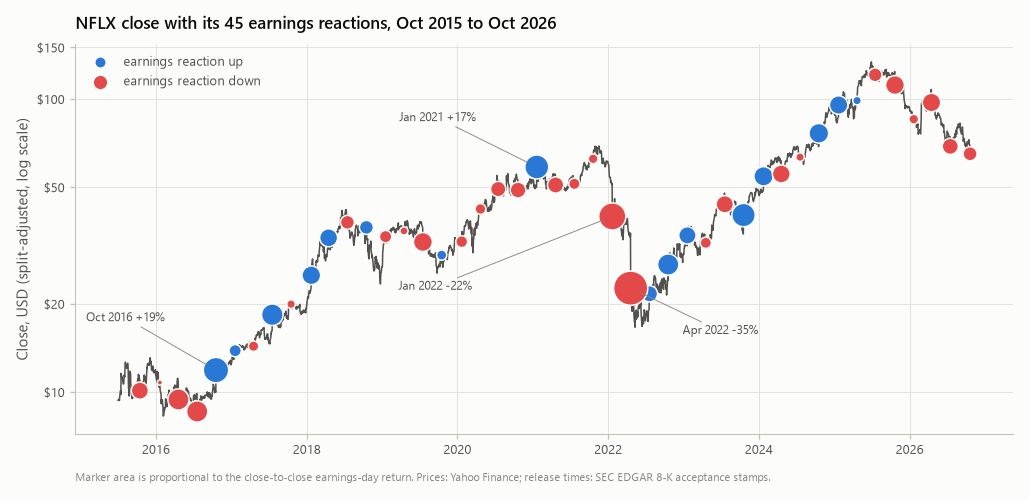

In [37]:
def save(fig, name):
    fig.savefig(CHARTS / name)
    plt.show()
    plt.close(fig)


def log_ticks(ax, ticks, axis="y", fmt="{:g}%"):
    a = ax.yaxis if axis == "y" else ax.xaxis
    a.set_major_locator(FixedLocator(ticks))
    a.set_minor_locator(NullLocator())
    a.set_major_formatter(FuncFormatter(lambda v, _: fmt.format(v)))


# Chart 1 - price with earnings reactions
fig, ax = plt.subplots(figsize=(11, 4.6))
s = nf["close_a"].loc["2015-07-01":]
ax.plot(s.index, s.to_numpy(), color=vz.INK2, lw=1.0)
ax.set_yscale("log")
mv = np.expm1(nf["r"].to_numpy()[p])
xe, ye = nev["react"].to_numpy(), nf["close_a"].to_numpy()[p]
size = 10 + 1400 * np.abs(mv)
up = mv > 0
ax.scatter(xe[up], ye[up], s=size[up], color=vz.BLUE, edgecolor=vz.SURFACE, linewidth=1.0, zorder=3,
           label="earnings reaction up")
ax.scatter(xe[~up], ye[~up], s=size[~up], color=vz.RED, edgecolor=vz.SURFACE, linewidth=1.0, zorder=3,
           label="earnings reaction down")
label_offsets = {"2016-10": (-85, 32), "2021-01": (-90, 30), "2022-01": (-140, -48), "2022-04": (34, -30)}
for j in np.argsort(-np.abs(mv))[:4]:
    dt_ = pd.Timestamp(xe[j])
    off = label_offsets.get(dt_.strftime("%Y-%m"), (-80, 30) if mv[j] > 0 else (34, -30))
    ax.annotate(f"{dt_:%b %Y} {100 * mv[j]:+.0f}%", (xe[j], ye[j]), xytext=off, textcoords="offset points",
                fontsize=8, color=vz.INK2,
                arrowprops=dict(arrowstyle="-", color=vz.MUTED, lw=0.6, shrinkA=0, shrinkB=7))
log_ticks(ax, [5, 10, 20, 50, 100, 150], fmt="${:g}")
ax.set_ylabel("Close, USD (split-adjusted, log scale)")
ax.set_title("NFLX close with its 45 earnings reactions, Oct 2015 to Oct 2026")
ax.legend(loc="upper left", markerscale=0.6)
vz.note(ax, "Marker area is proportional to the close-to-close earnings-day return. Prices: Yahoo Finance; "
            "release times: SEC EDGAR 8-K acceptance stamps.", y=-0.1)
save(fig, "01_price_with_earnings.png")

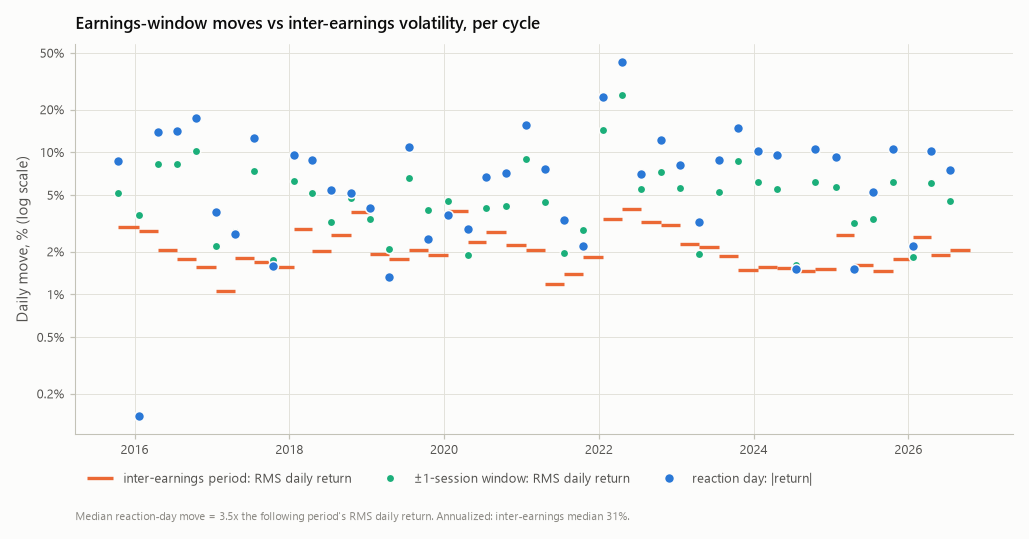

In [38]:
# Chart 2 - per-cycle volatility: earnings windows vs inter-earnings periods
fig, ax = plt.subplots(figsize=(11, 4.6))
rx = pd.to_datetime(pe["react"])
inter_rms = 100 * np.sqrt(cyc["rv_inter"] / cyc["n_inter_days"])
starts = pd.to_datetime(cyc["react_date"])
ends = pd.to_datetime(cyc["next_react_date"])
ax.hlines(inter_rms, starts, ends, color=vz.ORANGE, lw=2.2, label="inter-earnings period: RMS daily return")
ax.plot(rx, pe["rms_pm1_%"], "o", color=vz.AQUA, ms=5.5, mec=vz.SURFACE, mew=1.0,
        label="±1-session window: RMS daily return")
ax.plot(rx, pe["abs_R_%"], "o", color=vz.BLUE, ms=6.5, mec=vz.SURFACE, mew=1.0,
        label="reaction day: |return|")
ax.set_yscale("log")
log_ticks(ax, [0.2, 0.5, 1, 2, 5, 10, 20, 50])
ax.set_ylabel("Daily move, % (log scale)")
ax.set_title("Earnings-window moves vs inter-earnings volatility, per cycle")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.07), ncol=3)
med_ratio = np.median(pe["abs_R_%"] / inter_rms.to_numpy())
vz.note(ax, f"Median reaction-day move = {med_ratio:.1f}x the following period's RMS daily return. "
            f"Annualized: inter-earnings median {100 * cyc['vol_inter_ann'].median():.0f}%.", y=-0.2)
save(fig, "02_cycle_volatility.png")

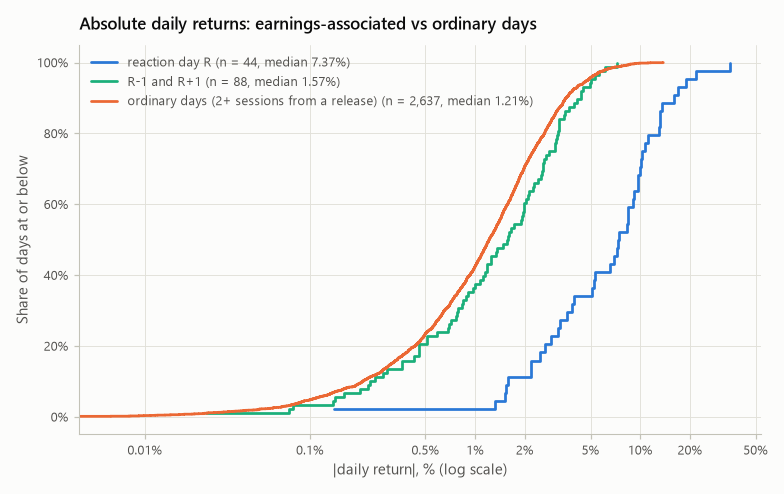

In [39]:
# Chart 3 - distribution of absolute daily returns
fig, ax = plt.subplots(figsize=(8, 4.6))
groups = [("reaction day R", D["rel"] == 0, vz.BLUE),
          ("R-1 and R+1", D["rel"].abs() == 1, vz.AQUA),
          ("ordinary days (2+ sessions from a release)", D["rel"].abs() >= 2, vz.ORANGE)]
for name, m, col in groups:
    a = np.sort(np.abs(np.expm1(D.loc[m, "r"].to_numpy()))) * 100
    yv = np.arange(1, len(a) + 1) / len(a)
    ax.step(a, yv, where="post", color=col, lw=1.8, label=f"{name} (n = {len(a):,}, median {np.median(a):.2f}%)")
ax.set_xscale("log")
log_ticks(ax, [0.01, 0.1, 0.5, 1, 2, 5, 10, 20, 50], axis="x")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{100 * v:.0f}%"))
ax.set_xlabel("|daily return|, % (log scale)")
ax.set_ylabel("Share of days at or below")
ax.set_title("Absolute daily returns: earnings-associated vs ordinary days")
ax.legend(loc="upper left")
save(fig, "03_abs_return_distribution.png")

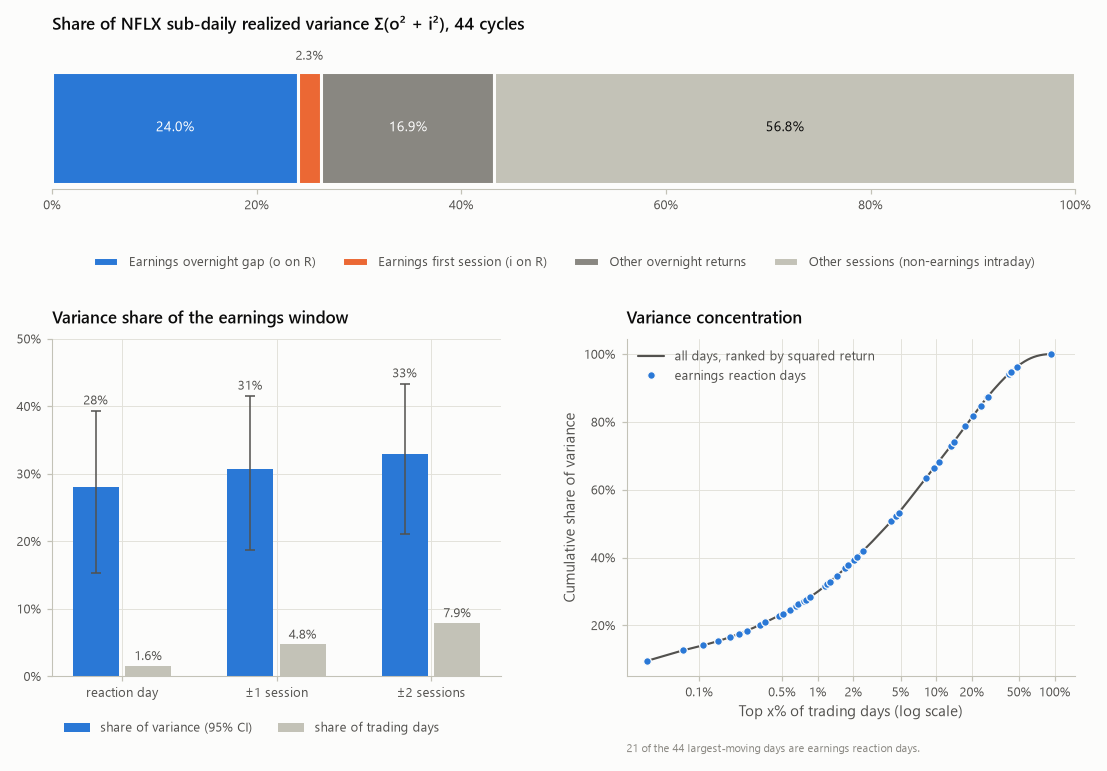

In [40]:
# Chart 4 - variance contribution
fig = plt.figure(figsize=(12, 7.2))
gs = GridSpec(2, 2, height_ratios=[0.8, 2.2], hspace=0.65, wspace=0.28)
ax0 = fig.add_subplot(gs[0, :])
shares = 100 * sub / sub.sum()
cols4 = [vz.BLUE, vz.ORANGE, vz.GRAY_DARK, vz.GRAY]
left = 0.0
for (name, val), col in zip(shares.items(), cols4):
    ax0.barh([0], [val], left=left, color=col, edgecolor=vz.SURFACE, linewidth=2, height=0.5, label=name)
    if val > 6:
        ax0.text(left + val / 2, 0, f"{val:.1f}%", ha="center", va="center", fontsize=9,
                 color="white" if col in (vz.BLUE, vz.GRAY_DARK) else vz.INK)
    else:
        ax0.annotate(f"{val:.1f}%", (left + val / 2, 0.25), xytext=(0, 8), textcoords="offset points",
                     ha="center", fontsize=8.5, color=vz.INK2)
    left += val
ax0.set_xlim(0, 100)
ax0.set_yticks([])
ax0.grid(False)
ax0.spines["left"].set_visible(False)
ax0.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax0.set_title("Share of NFLX sub-daily realized variance Σ(o² + i²), 44 cycles", pad=24)
ax0.legend(loc="upper center", bbox_to_anchor=(0.5, -0.45), ncol=4)

ax1 = fig.add_subplot(gs[1, 0])
xw = np.arange(3)
sh = dec["share_of_variance_%"].to_numpy()
err = np.vstack([sh - dec["ci95_lo_%"].to_numpy(), dec["ci95_hi_%"].to_numpy() - sh])
ax1.bar(xw - 0.17, sh, width=0.3, color=vz.BLUE, label="share of variance (95% CI)")
ax1.errorbar(xw - 0.17, sh, yerr=err, fmt="none", ecolor=vz.INK2, elinewidth=1, capsize=3)
ax1.bar(xw + 0.17, dec["day_fraction_%"], width=0.3, color=vz.GRAY, label="share of trading days")
for xi_, v, hi_ in zip(xw, sh, dec["ci95_hi_%"].to_numpy()):
    ax1.text(xi_ - 0.17, hi_ + 1.0, f"{v:.0f}%", ha="center", fontsize=8.5, color=vz.INK2)
for xi_, v in zip(xw, dec["day_fraction_%"]):
    ax1.text(xi_ + 0.17, v + 0.8, f"{v:.1f}%", ha="center", fontsize=8.5, color=vz.INK2)
ax1.set_xticks(xw, ["reaction day", "±1 session", "±2 sessions"])
ax1.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax1.set_ylim(0, 50)
ax1.set_title("Variance share of the earnings window")
ax1.legend(loc="upper left", bbox_to_anchor=(0, -0.1), ncol=2)

ax2 = fig.add_subplot(gs[1, 1])
r2 = (D["r"] ** 2).to_numpy()
isr = (D["rel"] == 0).to_numpy()
o_ = np.argsort(-r2)
cum_share = np.cumsum(r2[o_]) / r2.sum()
frac = np.arange(1, len(r2) + 1) / len(r2)
ax2.plot(100 * frac, 100 * cum_share, color=vz.INK2, lw=1.4, label="all days, ranked by squared return")
ax2.plot(100 * frac[isr[o_]], 100 * cum_share[isr[o_]], "o", color=vz.BLUE, ms=5, mec=vz.SURFACE, mew=0.8,
         label="earnings reaction days")
ax2.set_xscale("log")
log_ticks(ax2, [0.1, 0.5, 1, 2, 5, 10, 20, 50, 100], axis="x")
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax2.set_xlabel("Top x% of trading days (log scale)")
ax2.set_ylabel("Cumulative share of variance")
top44 = int(isr[o_][:K].sum())
ax2.set_title("Variance concentration")
ax2.legend(loc="upper left")
vz.note(ax2, f"{top44} of the {K} largest-moving days are earnings reaction days.", y=-0.2)
save(fig, "04_variance_decomposition.png")

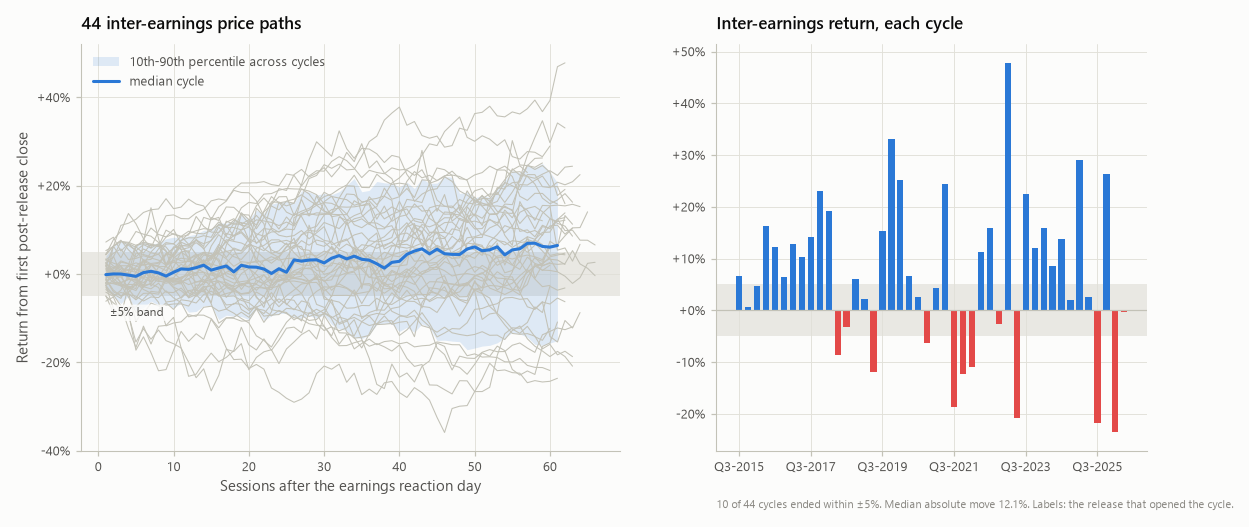

In [41]:
# Chart 5 - paths between earnings and their end points
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
paths = []
for k in range(len(cyc)):
    inter = nf.loc[(lab["cycle"] == k) & (lab["since"] >= 1)]
    p0 = nf.loc[pd.Timestamp(cyc.loc[k, "react_date"]), "close_a"]
    paths.append(100 * (inter["close_a"].to_numpy() / p0 - 1))
M = np.full((len(paths), max(map(len, paths))), np.nan)
for j, pth in enumerate(paths):
    M[j, :len(pth)] = pth
    ax.plot(np.arange(1, len(pth) + 1), pth, color=vz.GRAY, lw=0.7)
tt = np.arange(1, M.shape[1] + 1)
okc = (~np.isnan(M)).sum(0) >= 30
ax.axhspan(-5, 5, color=vz.GRID, alpha=0.7, lw=0)
ax.fill_between(tt[okc], np.nanpercentile(M, 10, 0)[okc], np.nanpercentile(M, 90, 0)[okc], color=vz.BLUE,
                alpha=0.14, lw=0, label="10th-90th percentile across cycles")
ax.plot(tt[okc], np.nanmedian(M, 0)[okc], color=vz.BLUE, lw=2, label="median cycle")
ax.text(1.5, -9.5, "±5% band", fontsize=8, color=vz.INK2,
        bbox=dict(boxstyle="round,pad=0.2", fc=vz.SURFACE, ec="none", alpha=0.85))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:+.0f}%"))
ax.set_xlabel("Sessions after the earnings reaction day")
ax.set_ylabel("Return from first post-release close")
ax.set_title("44 inter-earnings price paths")
ax.legend(loc="upper left")

ax = axes[1]
ci_ = 100 * cyc["cum_inter"].to_numpy()
xx = np.arange(len(ci_))
ax.axhspan(-5, 5, color=vz.GRID, alpha=0.7, lw=0)
ax.bar(xx, ci_, color=np.where(ci_ >= 0, vz.BLUE, vz.RED), width=0.7)
ax.axhline(0, color=vz.AXIS, lw=0.8)
lbl_idx = list(range(0, len(ci_), 8))
ax.set_xticks(lbl_idx, [cyc.loc[i, "quarter"] for i in lbl_idx])
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:+.0f}%"))
ax.set_title("Inter-earnings return, each cycle")
n5 = int((np.abs(ci_) < 5).sum())
vz.note(ax, f"{n5} of {len(ci_)} cycles ended within ±5%. Median absolute move "
            f"{np.median(np.abs(ci_)):.1f}%. Labels: the release that opened the cycle.", y=-0.12)
save(fig, "05_inter_earnings_paths.png")

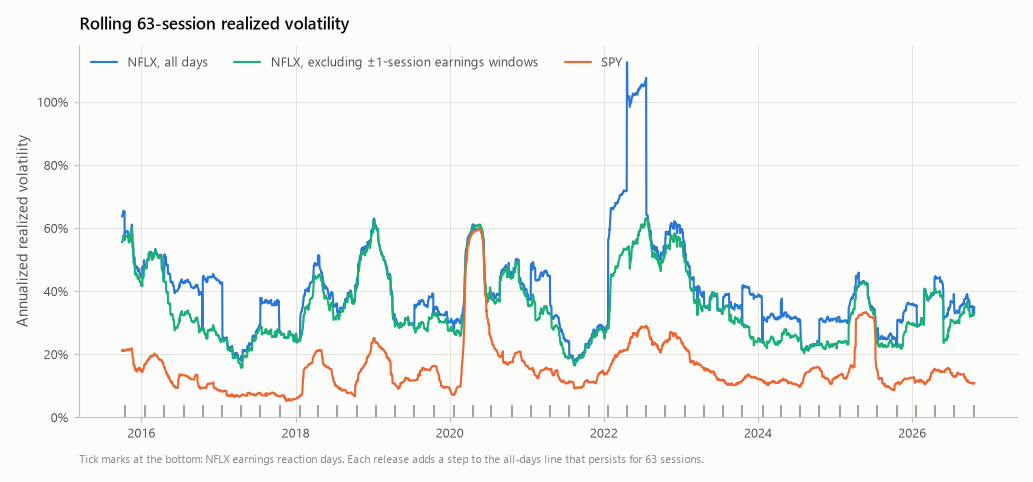

In [42]:
# Chart 6 - rolling realized volatility
fig, ax = plt.subplots(figsize=(11, 4.4))
win = 63
roll_all = 100 * np.sqrt(ANN * (nf["r"] ** 2).rolling(win).mean())
roll_ex = 100 * np.sqrt(ANN * (r_ex ** 2).rolling(win, min_periods=50).mean())
roll_spy = 100 * np.sqrt(ANN * (SPY_r ** 2).rolling(win).mean())
sl = slice("2015-10-01", None)
ax.plot(roll_all.loc[sl].index, roll_all.loc[sl].to_numpy(), color=vz.BLUE, lw=1.4, label="NFLX, all days")
ax.plot(roll_ex.loc[sl].index, roll_ex.loc[sl].to_numpy(), color=vz.AQUA, lw=1.4,
        label="NFLX, excluding ±1-session earnings windows")
ax.plot(roll_spy.loc[sl].index, roll_spy.loc[sl].to_numpy(), color=vz.ORANGE, lw=1.4, label="SPY")
ax.plot(nev["react"], np.full(len(nev), 2.0), "|", color=vz.GRAY_DARK, ms=8)
ax.set_ylim(0, None)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_ylabel("Annualized realized volatility")
ax.set_title("Rolling 63-session realized volatility")
ax.legend(loc="upper left", ncol=3)
vz.note(ax, "Tick marks at the bottom: NFLX earnings reaction days. Each release adds a step to the "
            "all-days line that persists for 63 sessions.", y=-0.1)
save(fig, "06_rolling_volatility.png")

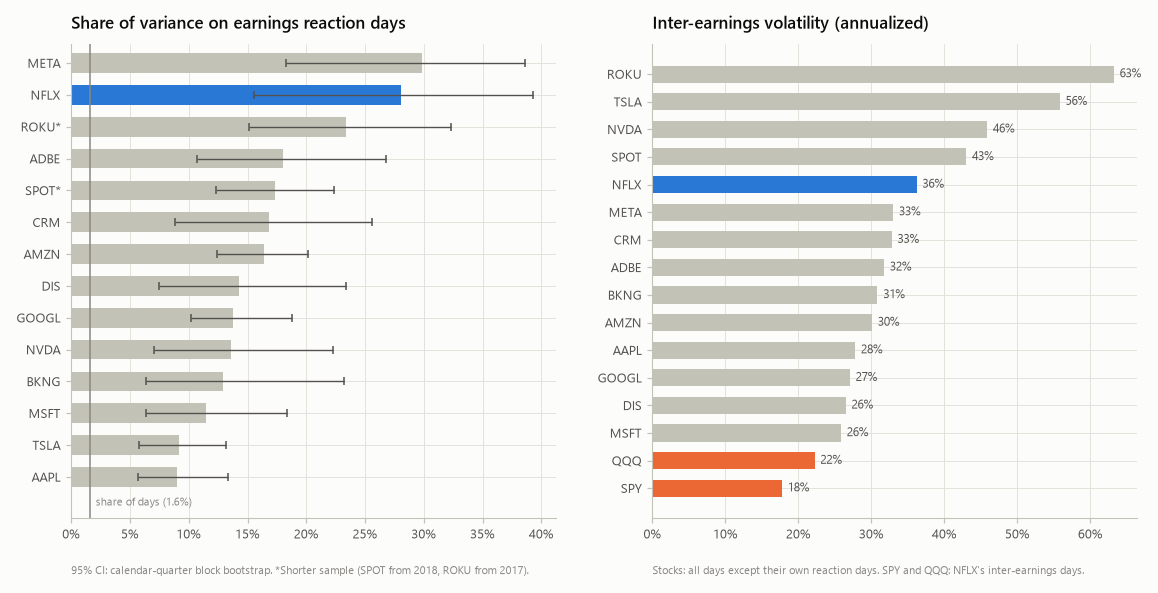

In [43]:
# Chart 7 - NFLX vs benchmarks
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.6))
ax = axes[0]
srt = xs.sort_values("share0")
cis = np.array([evol.ci(BT[("r", t)]["share0"]) for t in srt.index]) * 100
yy = np.arange(len(srt))
colors = [vz.BLUE if t == "NFLX" else vz.GRAY for t in srt.index]
ax.barh(yy, srt["share0"], color=colors, height=0.62)
ax.errorbar(srt["share0"], yy, xerr=np.vstack([srt["share0"] - cis[:, 0], cis[:, 1] - srt["share0"]]),
            fmt="none", ecolor=vz.INK2, elinewidth=0.9, capsize=2.5)
ax.axvline(100 * st["dayfrac0"], color=vz.MUTED, lw=1)
ax.text(100 * st["dayfrac0"] + 0.5, -0.9, "share of days (1.6%)", fontsize=7.5, color=vz.MUTED)
ax.set_yticks(yy, [f"{t}" + ("*" if t in ("SPOT", "ROKU") else "") for t in srt.index])
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_title("Share of variance on earnings reaction days")
ax.set_ylim(-1.3, len(srt) - 0.4)
vz.note(ax, "95% CI: calendar-quarter block bootstrap. *Shorter sample (SPOT from 2018, ROKU from 2017).", y=-0.1)

ax = axes[1]
iv = pd.concat([xs["vol_inter"], pd.Series({b: bench_tab.loc[b, "vol_on_NFLX_inter_days"] for b in BENCH})])
iv = iv.sort_values()
colors = [vz.BLUE if t == "NFLX" else (vz.ORANGE if t in BENCH else vz.GRAY) for t in iv.index]
ax.barh(np.arange(len(iv)), iv.to_numpy(), color=colors, height=0.62)
for j, (t, v) in enumerate(iv.items()):
    ax.text(v + 0.8, j, f"{v:.0f}%", va="center", fontsize=8, color=vz.INK2)
ax.set_yticks(np.arange(len(iv)), iv.index)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_title("Inter-earnings volatility (annualized)")
vz.note(ax, "Stocks: all days except their own reaction days. SPY and QQQ: NFLX's inter-earnings days.", y=-0.1)
save(fig, "07_peer_comparison.png")

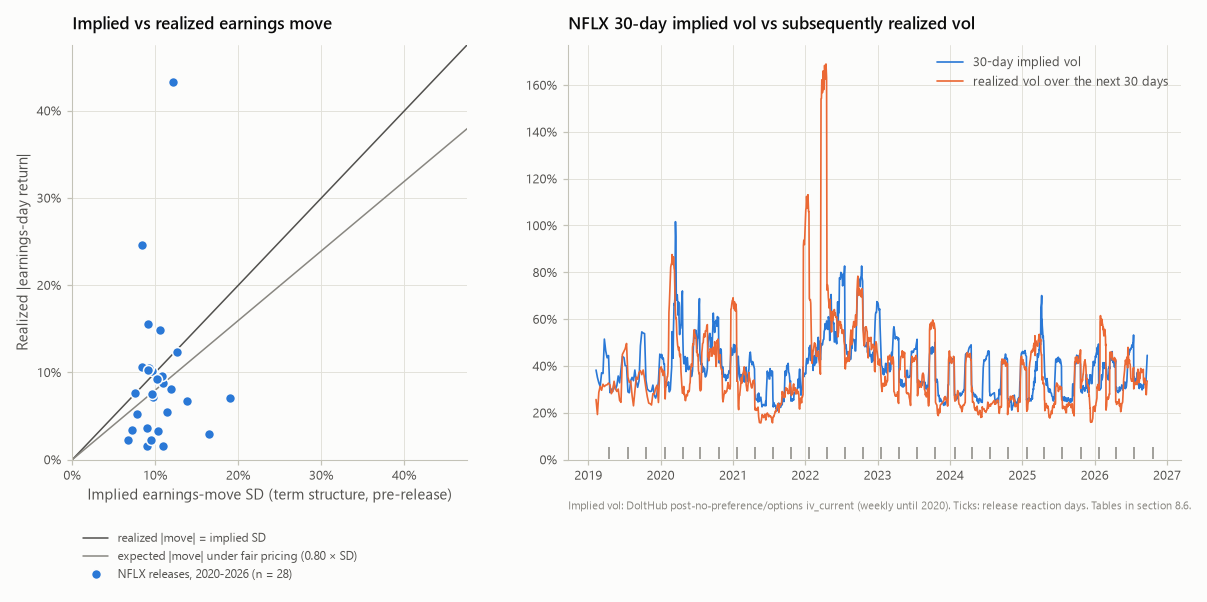

In [44]:
# Chart 8 - options: implied vs realized
fig, axes = plt.subplots(1, 2, figsize=(13, 4.9), gridspec_kw={"width_ratios": [1, 1.55]})
ax = axes[0]
okp = ev_opt.dropna(subset=["J_implied"])
lim = 1.1 * 100 * max(okp["abs_r_R"].max(), okp["J_implied"].max())
ax.plot([0, lim], [0, lim], color=vz.INK2, lw=1, label="realized |move| = implied SD")
ax.plot([0, lim], [0, lim * np.sqrt(2 / np.pi)], color=vz.GRAY_DARK, lw=1,
        label="expected |move| under fair pricing (0.80 × SD)")
ax.plot(100 * okp["J_implied"], 100 * okp["abs_r_R"], "o", color=vz.BLUE, ms=6.5, mec=vz.SURFACE, mew=1.0,
        label=f"NFLX releases, 2020-2026 (n = {len(okp)})")
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_xlabel("Implied earnings-move SD (term structure, pre-release)")
ax.set_ylabel("Realized |earnings-day return|")
ax.set_title("Implied vs realized earnings move")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.15), fontsize=8)

ax = axes[1]
ax.plot(vrp.index, 100 * vrp["iv"].to_numpy(), color=vz.BLUE, lw=1.1, label="30-day implied vol")
ax.plot(vrp.index, 100 * vrp["rv"].to_numpy(), color=vz.ORANGE, lw=1.1, label="realized vol over the next 30 days")
ax.plot(reacts[reacts >= vrp.index[0]], np.full(int((reacts >= vrp.index[0]).sum()), 3.0), "|",
        color=vz.GRAY_DARK, ms=8)
ax.set_ylim(0, None)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_title("NFLX 30-day implied vol vs subsequently realized vol")
ax.legend(loc="upper right")
vz.note(ax, "Implied vol: DoltHub post-no-preference/options iv_current (weekly until 2020). Ticks: release "
            "reaction days. Tables in section 8.6.", y=-0.1)
save(fig, "08_implied_vs_realized.png")

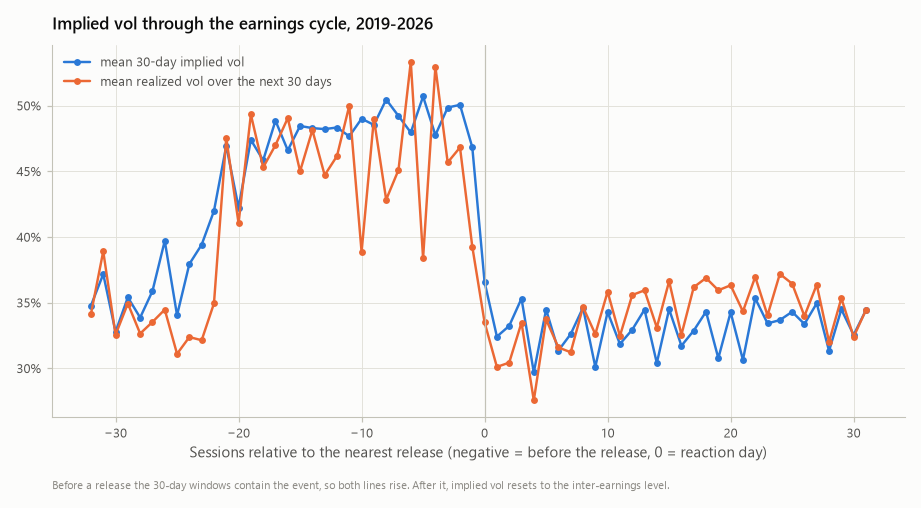

In [45]:
# Chart 8b - implied vol through the earnings cycle
prof_iv = vrp.copy()
prof_iv["offset"] = np.where(prof_iv["to_R"] <= prof_iv["since_R"], -prof_iv["to_R"], prof_iv["since_R"])
prof_iv = prof_iv[prof_iv["offset"].abs() <= 40]
g_ = prof_iv.groupby("offset")[["iv", "rv"]].mean()
cnt = prof_iv.groupby("offset").size()
g_ = g_[cnt >= 8]
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(g_.index, 100 * g_["iv"], "-o", color=vz.BLUE, ms=3.5, lw=1.6, label="mean 30-day implied vol")
ax.plot(g_.index, 100 * g_["rv"], "-o", color=vz.ORANGE, ms=3.5, lw=1.6,
        label="mean realized vol over the next 30 days")
ax.axvline(0, color=vz.AXIS, lw=0.8)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_xlabel("Sessions relative to the nearest release (negative = before the release, 0 = reaction day)")
ax.set_title("Implied vol through the earnings cycle, 2019-2026")
ax.legend(loc="upper left")
vz.note(ax, "Before a release the 30-day windows contain the event, so both lines rise. After it, implied "
            "vol resets to the inter-earnings level.", y=-0.17)
save(fig, "08b_iv_through_cycle.png")

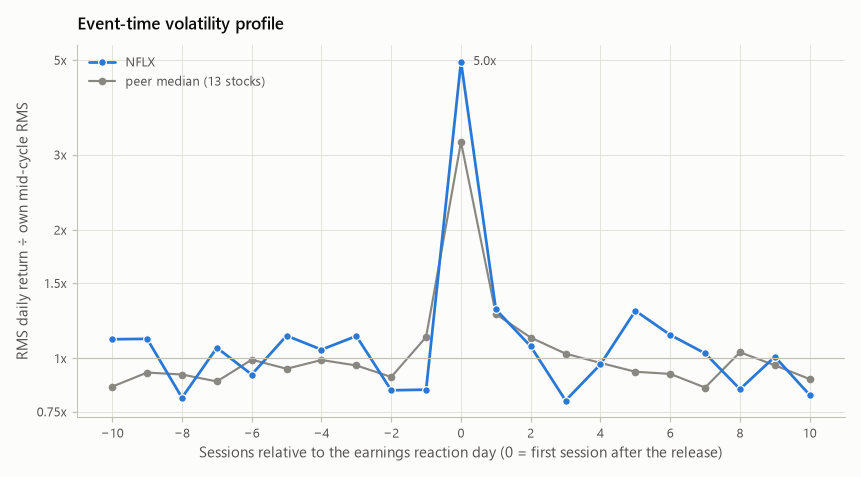

In [46]:
# Chart 9 - event-time volatility profile (NFLX vs peer median), relative to own mid-cycle RMS
def profile(df_, ev_):
    lb = evol.label_days(df_.index, ev_["react"])
    ok_ = (lb["cycle"] >= 0) & lb["complete"]
    rr = df_.loc[ok_, "r"]
    rl_ = lb.loc[ok_, "rel"]
    midm = (lb.loc[ok_, "since"] >= 6) & (lb.loc[ok_, "to_next"] >= 6)
    base = np.sqrt((rr[midm] ** 2).mean())
    pr_ = np.sqrt((rr ** 2).groupby(rl_).mean()).loc[-10:10] / base
    return pr_


prof_nf = profile(nf, nev)
prof_peers = pd.DataFrame({t: profile(px[t], EVENTS[t]) for t in PEERS})
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(prof_peers.index, prof_peers.median(axis=1), "-o", color=vz.GRAY_DARK, ms=4, lw=1.4,
        label="peer median (13 stocks)")
ax.plot(prof_nf.index, prof_nf.to_numpy(), "-o", color=vz.BLUE, ms=5, lw=1.8, mec=vz.SURFACE, mew=0.8,
        label="NFLX")
ax.axhline(1, color=vz.AXIS, lw=0.8)
ax.set_yscale("log")
log_ticks(ax, [0.5, 0.75, 1, 1.5, 2, 3, 5], fmt="{:g}x")
ax.set_xticks(range(-10, 11, 2))
ax.set_xlabel("Sessions relative to the earnings reaction day (0 = first session after the release)")
ax.set_ylabel("RMS daily return ÷ own mid-cycle RMS")
ax.set_title("Event-time volatility profile")
hh, ll = ax.get_legend_handles_labels()
ax.legend(hh[::-1], ll[::-1], loc="upper left")
ax.annotate(f"{prof_nf.loc[0]:.1f}x", (0, prof_nf.loc[0]), xytext=(8, 0), textcoords="offset points",
            fontsize=8.5, color=vz.INK2, va="center")
save(fig, "09_event_time_profile.png")

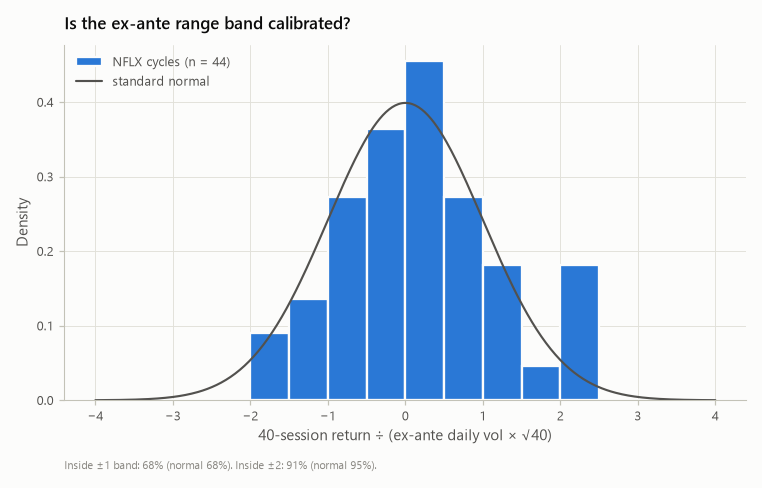

In [47]:
# Chart 10 - calibration of the ex-ante range band (H3)
fig, ax = plt.subplots(figsize=(8, 4.2))
bins = np.arange(-4, 4.01, 0.5)
ax.hist(fc["z_end"], bins=bins, color=vz.BLUE, edgecolor=vz.SURFACE, linewidth=1.5,
        weights=np.full(len(fc), 1 / (len(fc) * 0.5)), label=f"NFLX cycles (n = {len(fc)})")
zz = np.linspace(-4, 4, 400)
ax.plot(zz, stats.norm.pdf(zz), color=vz.INK2, lw=1.4, label="standard normal")
ax.set_xlabel("40-session return ÷ (ex-ante daily vol × √40)")
ax.set_ylabel("Density")
ax.set_title("Is the ex-ante range band calibrated?")
ax.legend(loc="upper left")
vz.note(ax, f"Inside ±1 band: {np.mean(np.abs(fc['z_end']) <= 1):.0%} (normal 68%). "
            f"Inside ±2: {np.mean(np.abs(fc['z_end']) <= 2):.0%} (normal 95%).", y=-0.17)
save(fig, "10_range_calibration.png")

## 10. Results summary

The headline numbers, collected in one place and written to `data/processed/summary.json` for the
report. Each verdict comes from an explicit rule on the estimates, so a data refresh updates the
verdicts with the numbers. The rules are printed next to each verdict.

In [48]:
spy_ratio = h1c.loc["NFLX / SPY"]
peer_ratio = h1c.loc["NFLX / peer_median"]
idio_ratio = h1c.loc["NFLX_idio / peer_median_idio"]
s0_ci = evol.ci(bt["share0"])
xs_share = xs_ci.loc["share of variance on reaction day"]
cov1 = float(np.mean(np.abs(fc["z_end"]) <= 1))
summary = {
    "sample": {"first_release": str(nev["ann_date"].iloc[0].date()), "last_release": str(nev["ann_date"].iloc[-1].date()),
               "releases": int(len(nev)), "complete_cycles": int(len(cyc)), "trading_days_in_blocks": int(len(D))},
    "earnings_moves": {"mean_abs_pct": float(100 * np.abs(np.expm1(r_R)).mean()),
                       "median_abs_pct": float(100 * np.median(np.abs(np.expm1(r_R)))),
                       "rms_log_pct": float(100 * np.sqrt(np.mean(r_R ** 2))),
                       "gap_share_of_earnings_day_var": float((o_R ** 2).sum() / (r_R ** 2).sum()),
                       "negative_reactions": f"{int((xr < 0).sum())}/{len(xr)}"},
    "H1": {"vol_core_ann_pct": 100 * st["vol_core_ann"], "vol_inter_ann_pct": 100 * st["vol_inter_ann"],
           "median_cycle_vol_pct": float(100 * cyc["vol_inter_ann"].median()),
           "nflx_over_spy": float(spy_ratio["pooled vol ratio"]), "nflx_over_spy_ci": [float(spy_ratio["ci95_lo"]), float(spy_ratio["ci95_hi"])],
           "nflx_over_peer_median": float(peer_ratio["pooled vol ratio"]),
           "nflx_over_peer_median_ci": [float(peer_ratio["ci95_lo"]), float(peer_ratio["ci95_hi"])],
           "idio_over_peer_median": float(idio_ratio["pooled vol ratio"]),
           "idio_over_peer_median_ci": [float(idio_ratio["ci95_lo"]), float(idio_ratio["ci95_hi"])],
           "rank_inter_vol_of_14": int(xs.loc["NFLX", "rank_vol_inter"])},
    "H2": {"share0_pct": 100 * st["share0"], "share0_ci_pct": [100 * s0_ci[0], 100 * s0_ci[1]],
           "share1_pct": 100 * st["share1"], "share2_pct": 100 * st["share2"],
           "dayfrac0_pct": 100 * st["dayfrac0"], "variance_multiple": st["mult"],
           "randomization_p": float(dec.loc["Reaction day only", "randomization_p"]),
           "share0_idio_pct": 100 * st_e["share0"],
           "share0_drop5_pct": float(rob.loc["drop 5 largest", "share0"]),
           "share0_first_half_pct": float(rob.loc["first half (cycles 0-21, 2015-2021)", "share0"]),
           "share0_second_half_pct": float(rob.loc["second half (cycles 22-43, 2021-2026)", "share0"]),
           "earnings_gap_share_subdaily_pct": float(100 * sub.iloc[0] / sub.sum())},
    "H3": {"coverage_1sigma": cov1, "coverage_2sigma": float(np.mean(np.abs(fc["z_end"]) <= 2)),
           "median_abs_forecast_error_pct": float(h3a.loc["median abs error %", "NFLX"]),
           "r2_oos_vs_expanding_mean": float(h3a.loc["R2_OOS vs expanding mean", "NFLX"]),
           "cv_cycle_vol": float(h3a.loc["CV of realized cycle vol", "NFLX"]),
           "earnings_move_spearman_trail4": float(h3c["Spearman(|move|, trailing-4 mean)"])},
    "H4": {"share0_minus_peer_median_pts": float(xs_share["diff"]),
           "ci": [float(xs_share["diff_ci95_lo"]), float(xs_share["diff_ci95_hi"])],
           "p_rank1": float(xs_share["P(NFLX ranks 1st)"]), "rank_share0_of_14": int(xs.loc["NFLX", "rank_share0"]),
           "spy_share_on_nflx_days_pct": float(bench_tab.loc["SPY", "share_of_var_on_NFLX_R_days"]),
           "peers_beaten_95": list(sig_above.index[sig_above["ci95_lo"] > 0])},
    "sideways": {"median_abs_cum_inter_pct": float(100 * np.median(np.abs(cyc["cum_inter"]))),
                 "share_abs_cum_lt5": float(np.mean(np.abs(cyc["cum_inter"]) < 0.05)),
                 "spy_share_abs_cum_lt5": float(h5a.loc["|cum| < 5%", "SPY (same days)"]),
                 "median_range_pct": float(100 * cyc["range_hl"].median()),
                 "mean_cum2_over_rv": float(h5b.iloc[1]),
                 "vr20": float(vr_rows["q=20"]["NFLX VR"]), "vr20_z": float(vr_rows["q=20"]["NFLX z"]),
                 "corr_earnings_vs_drift": float(cont["corr(earnings return, inter-period return)"])},
    "options": {"iv_crush_pts_mean": float(crush["crush_pts"].mean()),
                "vrp_inter_pts": float(vr_tab.loc["pure inter-earnings window", "mean IV-RV pts"]),
                "vrp_inter_ci": [float(vr_tab.loc["pure inter-earnings window", "ci95_lo"]),
                                 float(vr_tab.loc["pure inter-earnings window", "ci95_hi"])],
                "event_var_ratio_realized_over_implied": float(im["pooled realized/implied variance  Σr²/ΣJ²"]),
                "event_var_ratio_ci": [float(x) for x in evol.ci(np.array(bt_ratio))],
                "short_event_straddle_quoted_mean_pct": float(et.loc["short event straddle (sell bid, buy ask), quoted trades", "mean %"]),
                "short_event_straddle_all_best_case_mean_pct": float(et.loc["SHORT, all releases (unquoted exits at intrinsic: best case)", "mean %"]),
                "post_earnings_short_straddle_hedged_mean_pct": float(ss_tab.loc["delta-hedged, sold at bid", "mean %"]),
                "post_earnings_short_straddle_hedged_ci": [float(ss_tab.loc["delta-hedged, sold at bid", "ci95_lo %"]),
                                                           float(ss_tab.loc["delta-hedged, sold at bid", "ci95_hi %"])]},
}
import json  # noqa: E402

(PROC / "summary.json").write_text(json.dumps(summary, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)),
                                   encoding="utf-8")

h1_rule = spy_ratio["ci95_lo"] > 1 and peer_ratio["ci95_lo"] > 1
h2_rule = s0_ci[0] > 3 * st["dayfrac0"] and dec.loc["Reaction day only", "randomization_p"] < 0.01
h3_ok_cov = abs(cov1 - 0.683) <= 0.10
h4_vs_median = xs_share["diff_ci95_lo"] > 0
verdicts = pd.DataFrame([
    {"hypothesis": "H1 low inter-earnings volatility",
     "verdict": "REJECTED" if h1_rule else ("SUPPORTED" if spy_ratio["ci95_hi"] < 1 else "MIXED"),
     "rule": "NFLX/SPY and NFLX/peer-median vol ratio CIs both above 1 -> rejected",
     "evidence": f"inter-earnings vol {100 * st['vol_core_ann']:.0f}% ann.; {spy_ratio['pooled vol ratio']:.2f}x SPY "
                 f"[{spy_ratio['ci95_lo']:.2f}, {spy_ratio['ci95_hi']:.2f}]; {peer_ratio['pooled vol ratio']:.2f}x peer median"},
    {"hypothesis": "H2 earnings concentration",
     "verdict": "SUPPORTED" if h2_rule else "NOT SUPPORTED",
     "rule": "share CI lower bound > 3x the day fraction and randomization p < 0.01",
     "evidence": f"{100 * st['share0']:.0f}% of variance on {100 * st['dayfrac0']:.1f}% of days "
                 f"[{100 * s0_ci[0]:.0f}%, {100 * s0_ci[1]:.0f}%]; {st['mult']:.0f}x an ordinary day's variance"},
    {"hypothesis": "H3 predictable inter-earnings range",
     "verdict": "PARTIALLY SUPPORTED" if h3_ok_cov else "NOT SUPPORTED",
     "rule": "ex-ante ±1σ band coverage within 10 pts of 68% -> a range can be set; R2_OOS shows how much better than the long-run mean",
     "evidence": f"±1σ coverage {cov1:.0%}, ±2σ {np.mean(np.abs(fc['z_end']) <= 2):.0%}; median vol-forecast error "
                 f"{h3a.loc['median abs error %', 'NFLX']:.0f}%; R2_OOS {h3a.loc['R2_OOS vs expanding mean', 'NFLX']:.2f}"},
    {"hypothesis": "H4 unusual contrast vs peers/market",
     "verdict": ("PARTIALLY SUPPORTED" if h4_vs_median else "NOT SUPPORTED"),
     "rule": "share minus peer median CI above 0 -> above typical; P(rank 1) < 50% -> not unique",
     "evidence": f"rank {int(xs.loc['NFLX', 'rank_share0'])}/14; +{xs_share['diff']:.0f} pts vs peer median "
                 f"[{xs_share['diff_ci95_lo']:.0f}, {xs_share['diff_ci95_hi']:.0f}]; P(rank 1) {xs_share['P(NFLX ranks 1st)']:.0%}"},
    {"hypothesis": "'Trades flat' between earnings",
     "verdict": "REJECTED" if np.mean(np.abs(cyc["cum_inter"]) < 0.05) < 0.5 else "SUPPORTED",
     "rule": "fewer than half of cycles end within ±5% -> rejected",
     "evidence": f"median |inter-earnings move| {100 * np.median(np.abs(cyc['cum_inter'])):.0f}%; "
                 f"{np.mean(np.abs(cyc['cum_inter']) < 0.05):.0%} of cycles within ±5% (SPY {h5a.loc['|cum| < 5%', 'SPY (same days)']:.0%}); "
                 f"median high-low range {100 * cyc['range_hl'].median():.0f}%"},
])
pd.set_option("display.max_colwidth", 200)
display(verdicts.set_index("hypothesis"))
print(f"\nSummary written to {PROC / 'summary.json'}")

,verdict,rule,evidence
hypothesis,,,
H1 low inter-earnings volatility,REJECTED,NFLX/SPY and NFLX/peer-median vol ratio CIs both above 1 -> rejected,"inter-earnings vol 36% ann.; 2.04x SPY [1.69, 2.50]; 1.14x peer median"
H2 earnings concentration,SUPPORTED,share CI lower bound > 3x the day fraction and randomization p < 0.01,"28% of variance on 1.6% of days [15%, 39%]; 24x an ordinary day's variance"
H3 predictable inter-earnings range,PARTIALLY SUPPORTED,ex-ante ±1σ band coverage within 10 pts of 68% -> a range can be set; R2_OOS shows how much better than the long-run mean,"±1σ coverage 68%, ±2σ 91%; median vol-forecast error 21%; R2_OOS 0.02"
H4 unusual contrast vs peers/market,PARTIALLY SUPPORTED,share minus peer median CI above 0 -> above typical; P(rank 1) < 50% -> not unique,"rank 2/14; +14 pts vs peer median [2, 25]; P(rank 1) 35%"
'Trades flat' between earnings,REJECTED,fewer than half of cycles end within ±5% -> rejected,median |inter-earnings move| 12%; 23% of cycles within ±5% (SPY 41%); median high-low range 26%



Summary written to data/processed/summary.json
